<a href="https://colab.research.google.com/github/minhphu12-oc/basic-python/blob/sklearn-project-for-machine-learning/project_8_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bước 1 : Phân tích dữ liệu

In [ ]:
import pandas as pd
df = pd.read_csv("UNSW_NB15_training-set.csv")

In [ ]:
# đọc 5 dòng đầu của dữ liệu
df.head(5)

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
df.shape

(175341, 45)

In [ ]:
# đọc thông tin dữ liệu
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [ ]:
# tìm giá trị thiếu
df.isnull().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [ ]:
# đọc trạng thái
df.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [ ]:
# xem phân bổ dữ liệu
df['label'].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [ ]:
df['attack_cat'].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [ ]:
df['service'].value_counts()

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

In [ ]:
df['is_ftp_login'].value_counts()

is_ftp_login
0    172774
1      2545
4        16
2         6
Name: count, dtype: int64

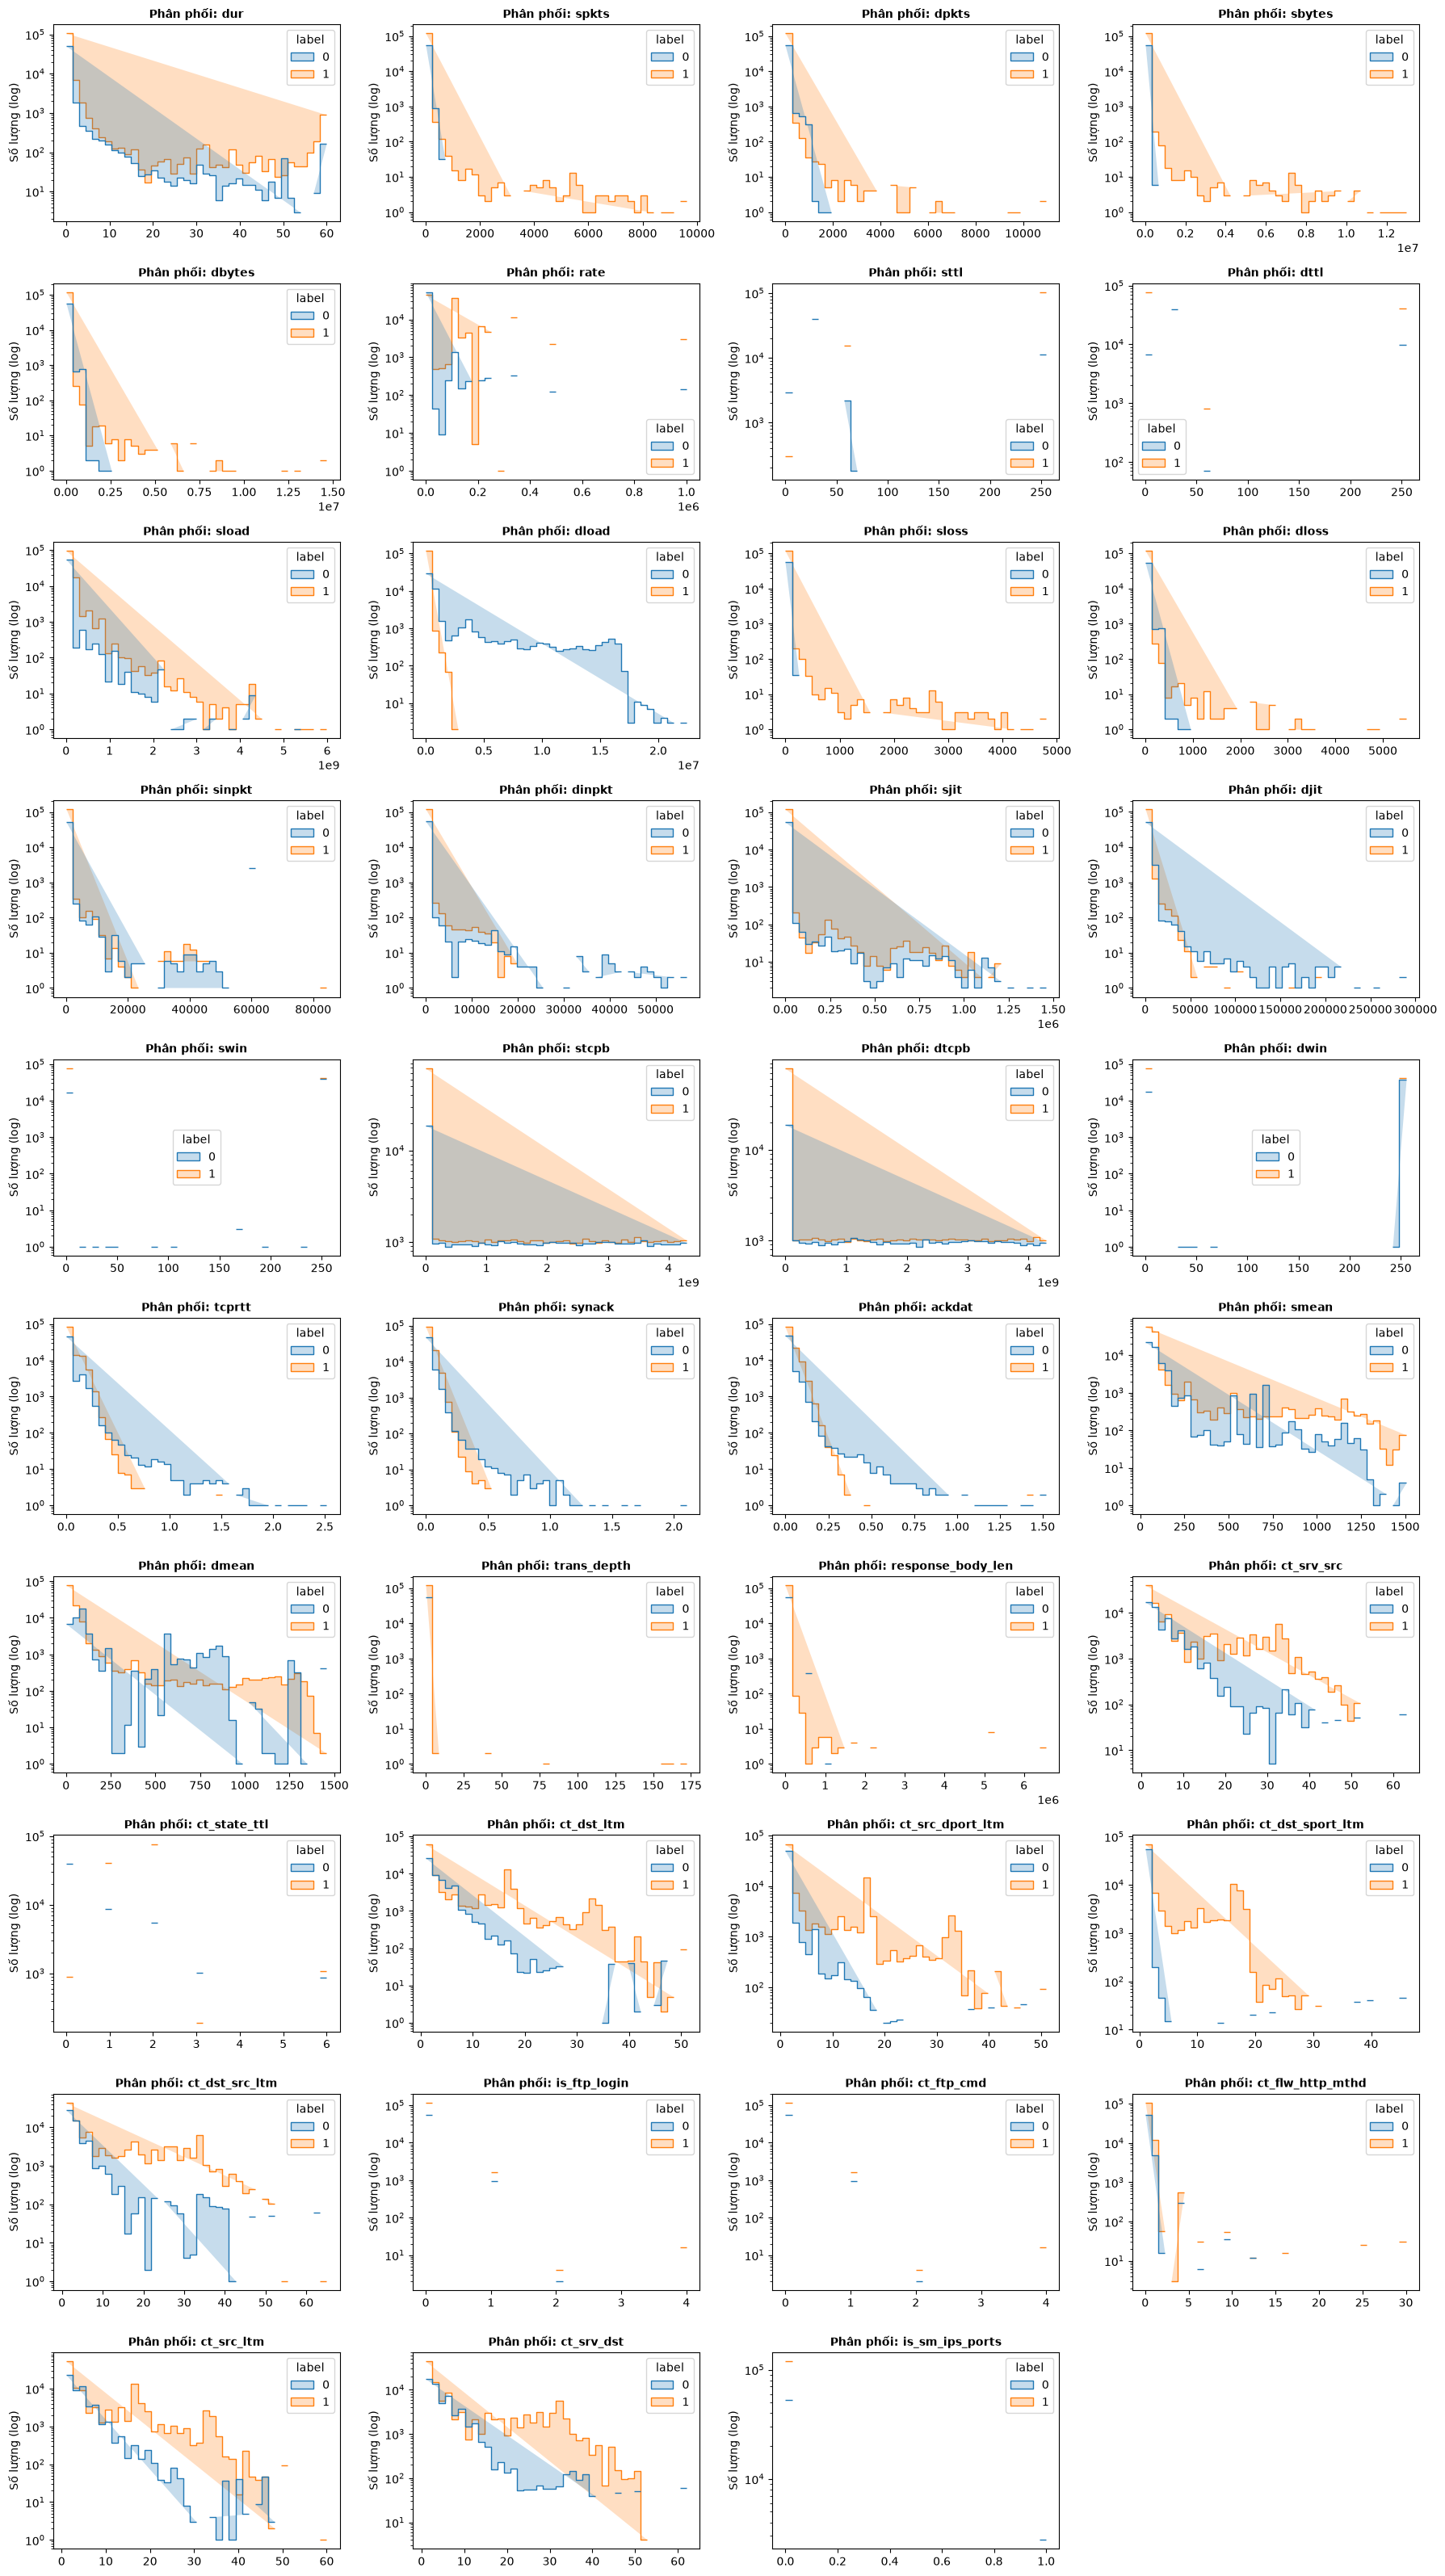

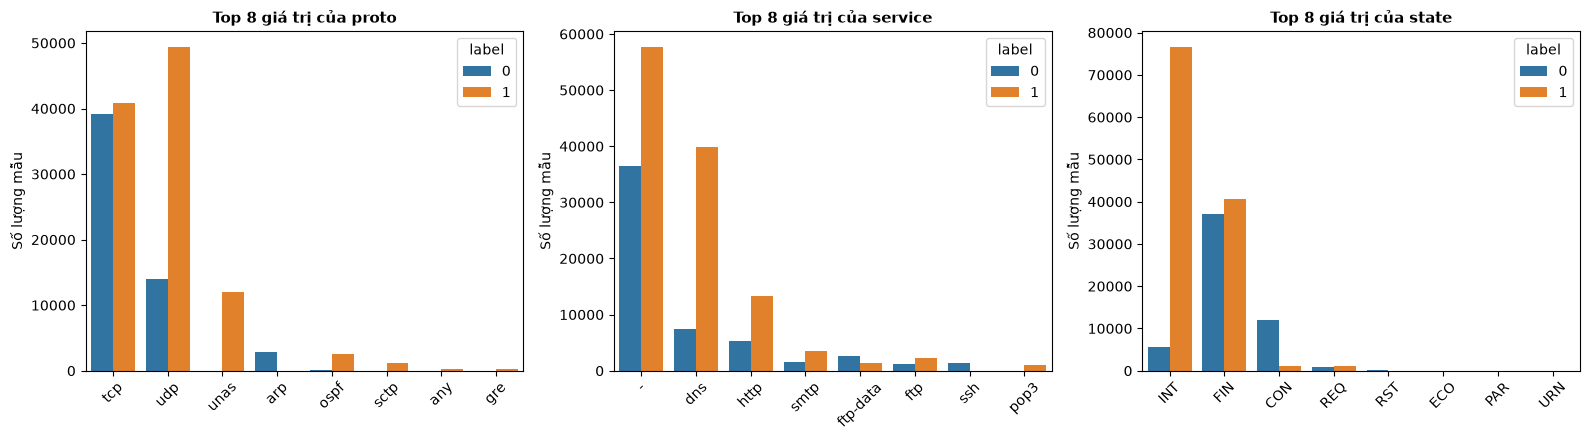

In [ ]:
# vẽ sự tương quan, độ lệch giữa các feature

import math
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

num_cols = df.select_dtypes(include=[np.number]).drop(columns=['id', 'label']).columns

n_cols = 4
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.2))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        data=df,
        x=col,
        hue='label',
        bins=40,
        ax=axes[i],
        log_scale=(False, True),
        element='step',
        palette={0: '#1f77b4', 1: '#ff7f0e'}
    )
    axes[i].set_title(f'Phân phối: {col}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng (log)')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

cat_cols = ['proto', 'service', 'state']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(cat_cols):
    top_vals = df[col].value_counts().head(8).index
    sns.countplot(
        data=df[df[col].isin(top_vals)],
        x=col,
        hue='label',
        order=top_vals,
        ax=axes[i],
        palette={0: '#1f77b4', 1: '#ff7f0e'}
    )
    axes[i].set_title(f'Top 8 giá trị của {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng mẫu')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

0 : an toàn

1 : tấn công

# Bước 2 : Xử lí dữ liệu

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = df.dropna(subset=['label'])

df = df.drop(columns=['id', 'attack_cat'], errors='ignore')

# Chuẩn hóa cờ nhị phân is_ftp_login (đưa giá trị > 0 về 1)
df['is_ftp_login'] = (df['is_ftp_login'] > 0).astype(int)

# Đổi ký tự '-' trong service thành 'unknown'
df['service'] = df['service'].replace('-', 'unknown')

# Loại bỏ các cột đa cộng tuyến mạnh (r > 0.96)
collinear_cols = ['ct_ftp_cmd', 'sloss', 'dloss', 'dwin', 'ct_srv_dst', 'ct_dst_src_ltm']
df = df.drop(columns=collinear_cols, errors='ignore')

# Gom nhóm các nhãn phân loại hiếm (< 100 mẫu) thành 'other'
for col in ['proto', 'service', 'state']:
    counts = df[col].value_counts()
    rare_labels = counts[counts < 100].index
    df[col] = df[col].replace(rare_labels, 'other')

x = df.drop(columns=['label'])
y = df['label']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

cat_cols = ['proto', 'service', 'state']
num_cols = x_train.select_dtypes(include=[np.number]).columns.tolist()

exclude_cols = ['is_ftp_login', 'is_sm_ips_ports']
num_cols = [col for col in num_cols if col not in exclude_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

x_train = preprocessor.fit_transform(x_train)
x_test = preprocessor.transform(x_test)

In [ ]:
print(x_train.shape)
print(x_test.shape)

(140272, 148)
(35069, 148)


# 10 Mô hình :
1. logistic regression
2. bayes
3. svm
4. decision tree
5. xgboost
6. SGD classifier
7. CNN
8. MLP
9. KNN
10. Tabnet

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import SGDClassifier
import itertools
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif

# Bước 3 : Train model

3.1 Feature selection

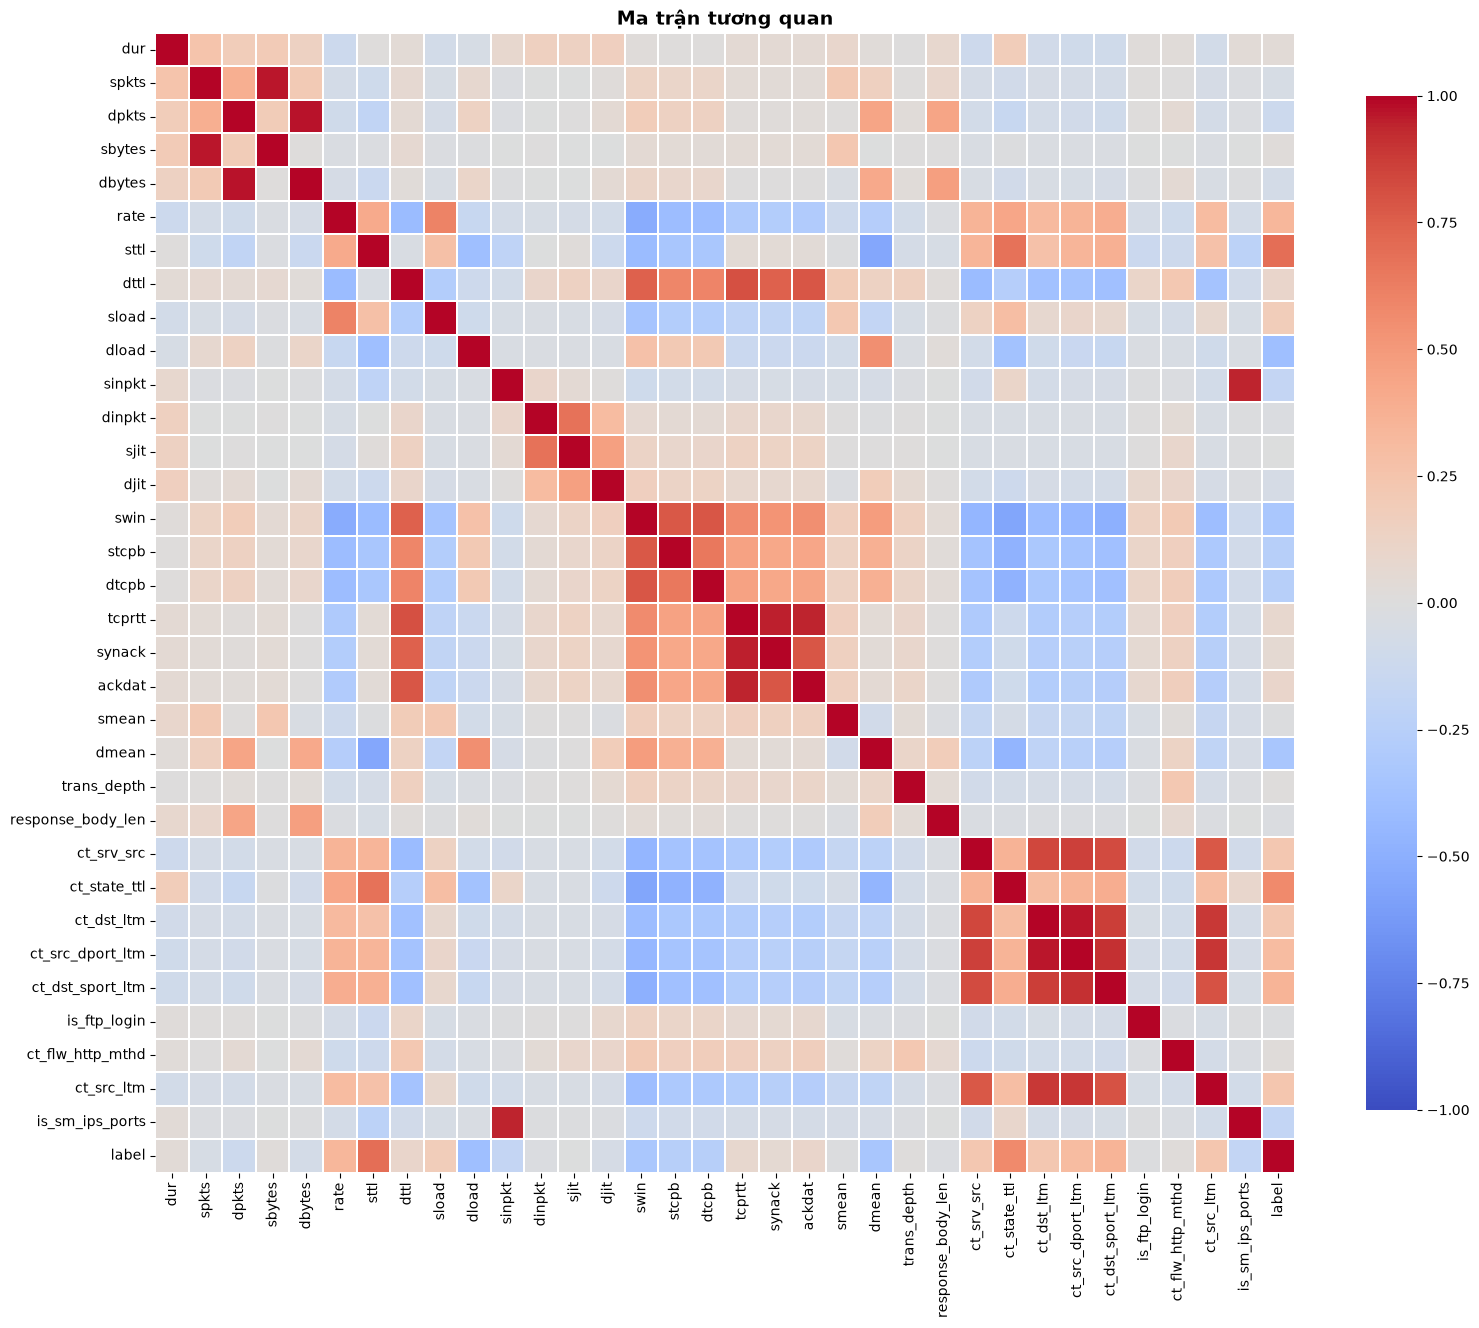

In [ ]:
# vẽ ma trận tương quan
corr = df.corr(numeric_only=True)
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={'shrink': 0.8}
)
plt.title('Ma trận tương quan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Hàm dùng chung cho các mô hình sklearn (metrics, AUC, ngưỡng, bảng so sánh từng không gian)

In [ ]:
import time
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

K_LIST = [4, 8, 16]
y_np = np.asarray(y_train)
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
feature_names = np.array([n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()])


def tinh_metrics(y_true, y_pred, score):
  return {
      'Accuracy': round(accuracy_score(y_true, y_pred), 4),
      'Precision': round(precision_score(y_true, y_pred), 4),
      'Recall': round(recall_score(y_true, y_pred), 4),
      'F1_Score': round(f1_score(y_true, y_pred), 4),
      'AUC': round(roc_auc_score(y_true, score), 4),
  }


def tim_nguong(y_true, probs):
  # ngưỡng cho F1 cao nhất trên OOF của tập train
  thresholds = np.arange(0.10, 0.91, 0.01)
  f1s = [f1_score(y_true, (probs >= t).astype(int)) for t in thresholds]
  return round(float(thresholds[int(np.argmax(f1s))]), 2)


def diem_so(model, X):
  # điểm số dùng để tính AUC (SVM dùng decision_function, không cần predict_proba)
  if hasattr(model, 'predict_proba'):
    return model.predict_proba(X)[:, 1]
  return model.decision_function(X)


def in_ket_qua(y_true, predict, score, best_params):
  for ten, v in tinh_metrics(y_true, predict, score).items():
    print(f'{ten}: {v}')
  print('Best param', best_params)
  ConfusionMatrixDisplay(confusion_matrix(y_true, predict), display_labels=[0, 1]).plot(cmap=plt.cm.Blues)


def in_feature_chon(k):
  sel = SelectKBest(f_classif, k=k).fit(x_train, y_train)
  idx = np.where(sel.get_support())[0]
  idx = idx[np.argsort(-sel.scores_[idx])]  # xếp theo điểm F giảm dần
  print(f'Feature được chọn (k={k}): ' + ', '.join(feature_names[idx]))


def khong_gian_sel(k, X_a, y_a, X_b):
  sel = SelectKBest(f_classif, k=k).fit(X_a, y_a)
  return sel.transform(X_a), sel.transform(X_b)


def bang_sklearn(grid, set_k, col_k, X_tr, X_te, dung_nguong=True):
  # dung_nguong=False (KNN, SVM): dùng predict mặc định; AUC vẫn tính từ điểm số
  rows = []
  for k in K_LIST:
    model = clone(grid.best_estimator_).set_params(**{set_k: k})
    row = {col_k: k}
    if dung_nguong:
      oof = cross_val_predict(model, X_tr, y_np, cv=st, method='predict_proba', n_jobs=-1)[:, 1]
      row['Best_Threshold'] = tim_nguong(y_np, oof)

    t0 = time.time()
    model.fit(X_tr, y_np)
    train_time = time.time() - t0

    t1 = time.time()
    if dung_nguong:
      y_pred = (model.predict_proba(X_te)[:, 1] >= row['Best_Threshold']).astype(int)
    else:
      y_pred = model.predict(X_te)
    infer_time_ms = (time.time() - t1) * 1000

    row.update(tinh_metrics(y_test, y_pred, diem_so(model, X_te)))
    row.update({'Train_Time_s': round(train_time, 4), 'Infer_Time_ms': round(infer_time_ms, 2)})
    rows.append(row)
  return pd.DataFrame(rows)

3.1.0 Các feature được chọn theo k

In [ ]:
for k in K_LIST:
  in_feature_chon(k)

Feature được chọn (k=4): sttl, ct_state_ttl, state_INT, dload
Feature được chọn (k=8): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


được chọn dựa vào ANOVA -F-value ( chia ra theo độ lệch chuẩn ) của f_classif selectkbest

sttl được chọn vì nó có độ tương quan +0.69 với label .Trên tập dữ liệu này, lưu lượng bình thường có giá trị trung vị sttl là 31 (trung bình ~75,4), trong khi lưu lượng tấn công có trung vị lên tới 254 (trung bình ~228,4)

ct_state_ttl có độ tương quan + 0.58 . Đếm số lượng kết nối có cùng trạng thái (state) và dải giá trị sttl/dttl. Khi tấn công xảy ra hàng loạt, các kết nối lặp lại cùng một cặp trạng thái và TTL bất thường khiến giá trị trung bình tăng vọt từ 0,50 (bình thường) lên 1,68 (tấn công).

state_INT (Trạng thái khởi tạo kết nối | Tương quan: +0,50): Biến nhị phân biểu thị kết nối chỉ mới ở trạng thái khởi tạo (INT) mà không hoàn tất bắt tay hay truyền dữ liệu hai chiều. Có tới 64,15% lưu lượng tấn công rơi vào trạng thái này (so với chỉ 10,21% ở lưu lượng bình thường), phản ánh các cuộc tấn công dò quét (Reconnaissance), làm ngập (DoS) hoặc gửi gói tin rác (Fuzzers/Generic) khiến đích đến không phản hồi.

dload (Destination bits per second — F-score: 32.170 | Tương quan: -0,39): Tốc độ tải dữ liệu từ đích về nguồn. Lưu lượng bình thường có băng thông tải về lớn (trung bình ~2,06 Mbps, trung vị ~336 Kbps), còn lưu lượng tấn công có trung vị bằng 0 (trung bình ~18,1 Kbps) do phần lớn các gói tấn công chỉ gửi một chiều và không nhận được luồng dữ liệu phản hồi.

3.1.1 Logistic Regression

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', LogisticRegression(max_iter = 3000, tol = 1e-3))
])
param_grid = [{
        'select__k': [4, 8, 16],
        'model__C': [0.01, 0.1, 1, 10]}]
grid_log = RandomizedSearchCV(pipeline, param_grid, n_iter=8, cv=st, scoring='f1', random_state=42)
grid_log.fit(x_train, y_train)
predict = grid_log.predict(x_test)

Accuracy: 0.9191
Precision: 0.8981
Recall: 0.994
F1_Score: 0.9436
AUC: 0.9563
Best param {'select__k': 16, 'model__C': 1}
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


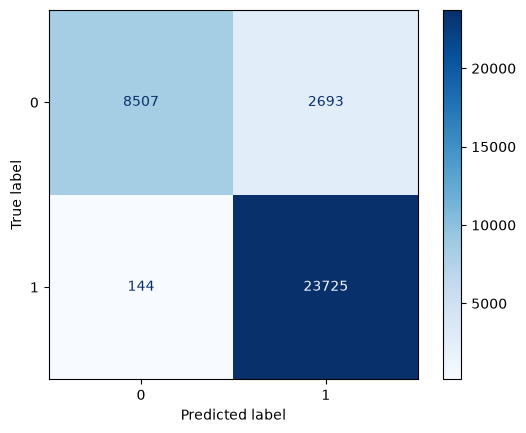

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_log, x_test), grid_log.best_params_)
in_feature_chon(grid_log.best_params_['select__k'])

In [ ]:
bang_sel_log = bang_sklearn(grid_log, 'select__k', 'So_Dac_Trung_k', x_train, x_test)
print(bang_sel_log.to_string(index=False))

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.31    0.8988     0.8792  0.9868    0.9299 0.9063        0.4143           9.83
              8            0.37    0.8861     0.8582  0.9974    0.9226 0.9232        0.5095          12.01
             16            0.56    0.9295     0.9133  0.9904    0.9503 0.9563        0.8987          15.22


3.1.2 Bayes

In [ ]:
pipeline = Pipeline(
    [('select', SelectKBest(f_classif)), ('model', GaussianNB())]
)

param_grid = [
    {'select__k': [4, 8, 16],
     'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}
]

grid_nb = RandomizedSearchCV(pipeline, param_grid, n_iter=8, cv=st, scoring='f1', random_state=42)
grid_nb.fit(x_train, y_train)
predict = grid_nb.predict(x_test)

Accuracy: 0.8871
Precision: 0.882
Recall: 0.963
F1_Score: 0.9207
AUC: 0.9167
Best param {'select__k': 4, 'model__var_smoothing': 1e-06}
Feature được chọn (k=4): sttl, ct_state_ttl, state_INT, dload


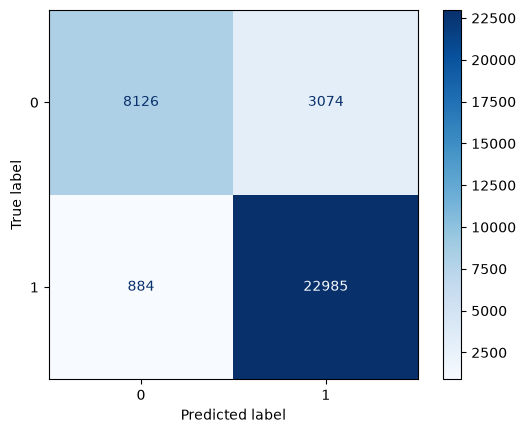

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_nb, x_test), grid_nb.best_params_)
in_feature_chon(grid_nb.best_params_['select__k'])

In [ ]:
bang_sel_nb = bang_sklearn(grid_nb, 'select__k', 'So_Dac_Trung_k', x_train, x_test)
print(bang_sel_nb.to_string(index=False))

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4             0.1    0.8959     0.8789  0.9824    0.9278 0.9167        0.3345          19.27
              8             0.1    0.8802     0.8832  0.9497    0.9152 0.9198        0.3411          20.42
             16             0.1    0.8070     0.8878  0.8202    0.8526 0.9039        0.4475          37.03


3.1.3 KNN

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])

param_grid = [{
    'select__k': [4, 8, 16],
    'model__n_neighbors': [3, 5, 7, 11],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
}]

grid_knn = RandomizedSearchCV(pipeline, param_grid, n_iter=20, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_knn.fit(x_train, y_train)
predict = grid_knn.predict(x_test)

Accuracy: 0.9352
Precision: 0.934
Recall: 0.9737
F1_Score: 0.9534
AUC: 0.9679
Best param {'select__k': 16, 'model__weights': 'distance', 'model__n_neighbors': 7, 'model__metric': 'euclidean'}
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


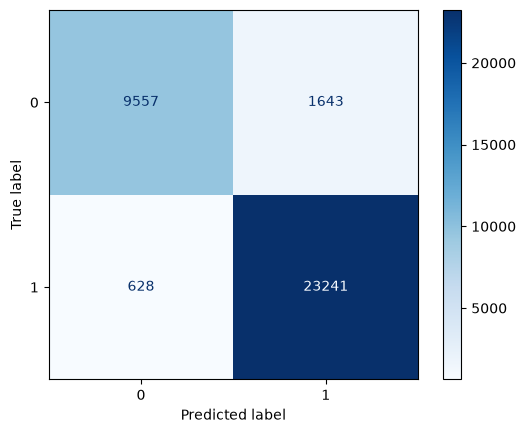

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_knn, x_test), grid_knn.best_params_)
in_feature_chon(grid_knn.best_params_['select__k'])

In [ ]:
bang_sel_knn = bang_sklearn(grid_knn, 'select__k', 'So_Dac_Trung_k', x_train, x_test, dung_nguong=False)
print(bang_sel_knn.to_string(index=False))

 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4    0.9171     0.9202  0.9615    0.9404 0.9409        0.8343       18267.75
              8    0.9256     0.9384  0.9533    0.9458 0.9638        0.8927        1437.38
             16    0.9352     0.9340  0.9737    0.9534 0.9679        0.3464        9344.14


3.1.4 SVM

In [ ]:
pipeline = Pipeline(
    [('select', SelectKBest(f_classif)), ('model', SVC(random_state=42))]
)

param_grid = [{
    'select__k': [4, 8, 16],
    'model__kernel': ['rbf'],
    'model__C': [0.1, 1, 10],
    'model__gamma': ['scale', 'auto']}]

grid_svm = RandomizedSearchCV(pipeline, param_grid, n_iter=5, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_svm.fit(x_train, y_train)
predict = grid_svm.predict(x_test)

Accuracy: 0.9334
Precision: 0.9135
Recall: 0.9965
F1_Score: 0.9532
AUC: 0.959
Best param {'select__k': 16, 'model__kernel': 'rbf', 'model__gamma': 'scale', 'model__C': 1}
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


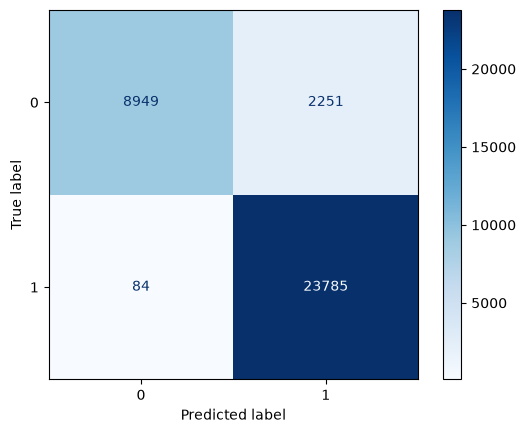

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_svm, x_test), grid_svm.best_params_)
in_feature_chon(grid_svm.best_params_['select__k'])

In [ ]:
bang_sel_svm = bang_sklearn(grid_svm, 'select__k', 'So_Dac_Trung_k', x_train, x_test, dung_nguong=False)
print(bang_sel_svm.to_string(index=False))

 So_Dac_Trung_k  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4    0.9280     0.9075  0.9956    0.9495 0.8646      246.0467       62701.86
              8    0.9309     0.9111  0.9955    0.9515 0.9385      307.2014       64754.35
             16    0.9334     0.9135  0.9965    0.9532 0.9590      794.5286       74768.50


3.1.5 DecisionTree

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', DecisionTreeClassifier(random_state=42)),
])

param_grid = [{
    'select__k': [4, 8, 16],
    'model__criterion': ['gini', 'entropy'],
    'model__splitter': ['best', 'random'],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced'],
}]

grid_dt = RandomizedSearchCV(pipeline, param_grid, n_iter=20, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_dt.fit(x_train, y_train)
predict = grid_dt.predict(x_test)

Accuracy: 0.938
Precision: 0.9269
Recall: 0.9866
F1_Score: 0.9558
AUC: 0.9824
Best param {'select__k': 16, 'model__splitter': 'best', 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': 10, 'model__criterion': 'gini', 'model__class_weight': None}
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


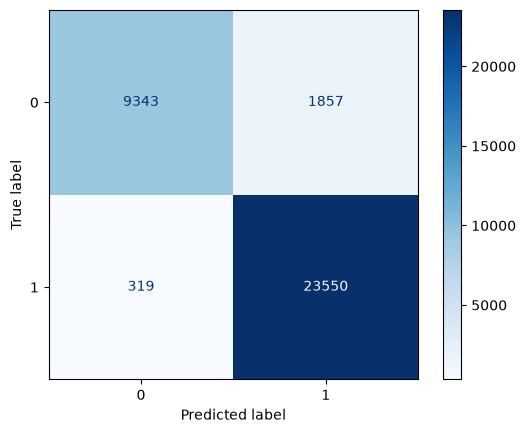

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_dt, x_test), grid_dt.best_params_)
in_feature_chon(grid_dt.best_params_['select__k'])

In [ ]:
bang_sel_dt = bang_sklearn(grid_dt, 'select__k', 'So_Dac_Trung_k', x_train, x_test)
print(bang_sel_dt.to_string(index=False))

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.24    0.9289     0.9076  0.9970    0.9502 0.9505        0.3340           9.90
              8            0.47    0.9343     0.9197  0.9899    0.9535 0.9755        0.4974          12.92
             16            0.48    0.9381     0.9256  0.9884    0.9560 0.9824        0.6741          14.62


3.1.6 XGB

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)),
])

param_grid = [{
    'select__k': [4, 8, 16],
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__scale_pos_weight': [1, 5],
}]

grid_xgb = RandomizedSearchCV(pipeline, param_grid, n_iter=20, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_xgb.fit(x_train, y_train)
predict = grid_xgb.predict(x_test)

Accuracy: 0.9427
Precision: 0.9345
Recall: 0.985
F1_Score: 0.959
AUC: 0.9849
Best param {'select__k': 16, 'model__subsample': 1.0, 'model__scale_pos_weight': 1, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


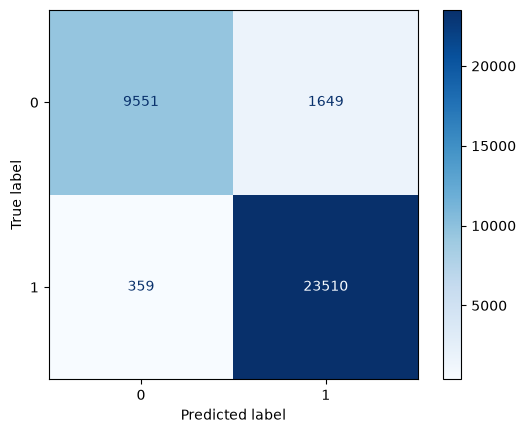

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_xgb, x_test), grid_xgb.best_params_)
in_feature_chon(grid_xgb.best_params_['select__k'])

In [ ]:
bang_sel_xgb = bang_sklearn(grid_xgb, 'select__k', 'So_Dac_Trung_k', x_train, x_test)
print(bang_sel_xgb.to_string(index=False))

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.53    0.9288     0.9077  0.9967    0.9502 0.9512        1.7358          64.27
              8            0.49    0.9365     0.9209  0.9918    0.9551 0.9775        2.3134          80.05
             16            0.49    0.9425     0.9330  0.9863    0.9589 0.9849        2.6120          71.17


Hàm huấn luyện deep learning (early stopping, giảm lr, trọng số tốt nhất), dùng chung cho SGD, MLP, CNN, TabNet ở 3.1, 3.2, 3.3

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)


def train_es(net, opt, loader, step_loss, val_score, epochs, patience, mode):
  # vòng lặp huấn luyện chung: early stopping + tự giảm lr + lấy lại trọng số tốt nhất
  # mode='max': điểm validation càng cao càng tốt (F1); mode='min': càng thấp càng tốt (loss)
  sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode=mode, factor=0.5, patience=2)
  sign = 1 if mode == 'max' else -1
  best, best_state, wait = None, None, 0
  for ep in range(epochs):
    net.train()
    for batch in loader:
      opt.zero_grad()
      step_loss(net, batch).backward()
      opt.step()
    net.eval()
    with torch.no_grad():
      score = val_score(net)
    sched.step(score)
    if best is None or sign * (score - best) > 1e-4:
      best, wait = score, 0
      best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
    else:
      wait += 1
      if wait >= patience:
        break
  net.load_state_dict(best_state)
  return net, best


def fit_torch_es(net, opt, X_tr, y_tr, epochs=50, patience=5, val_size=0.15):
  X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=val_size, random_state=42, stratify=y_tr)
  loader = DataLoader(TensorDataset(to_t(X_a), to_t(y_a)), batch_size=256, shuffle=True)
  Xv = to_t(X_v).to(device)
  crit = nn.BCEWithLogitsLoss()

  def step_loss(net, batch):
    bx, by = (t.to(device) for t in batch)
    return crit(net(bx).squeeze(-1), by)

  def val_f1(net):
    pred = (torch.sigmoid(net(Xv).squeeze(-1)) >= 0.5).cpu().numpy().astype(int)
    return f1_score(y_v, pred)

  return train_es(net, opt, loader, step_loss, val_f1, epochs, patience, 'max')[0]


def fit_tabnet_es(clf, X_tr, y_tr, max_epochs=100, patience=10, val_size=0.15):
  X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=val_size, random_state=42, stratify=y_tr)
  clf.fit(X_a, y_a, eval_set=[(X_v, y_v)], eval_name=['val'], eval_metric=['logloss'],
          max_epochs=max_epochs, patience=patience, batch_size=1024, virtual_batch_size=256)
  return clf


# mỗi hàm tao_* trả về (mạng, optimizer) từ bộ tham số p
def tao_sgd(p, in_f):
  net = TorchSGD(in_f).to(device)
  return net, torch.optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=p['weight_decay'])


def tao_mlp(p, in_f):
  net = TorchMLP(in_f, p['h1'], p['h2'], p['h2'] // 2, p['drop']).to(device)
  return net, torch.optim.AdamW(net.parameters(), lr=p['lr'], weight_decay=1e-4)


def tao_cnn(p, in_f):
  net = TorchCNN(in_f, p['filters'], p['ks'], p['drop']).to(device)
  return net, torch.optim.AdamW(net.parameters(), lr=p['lr'], weight_decay=1e-4)


# huan_luyen(p, X_a, y_a) trả về hàm du_doan(X_b) -> xác suất lớp 1
def tao_huan_luyen(tao_model):
  def huan_luyen(p, X_a, y_a):
    net, opt = tao_model(p, X_a.shape[1])
    net = fit_torch_es(net, opt, X_a, y_a, p['epochs']).eval()

    def du_doan(X_b):
      with torch.no_grad():
        return torch.sigmoid(net(to_t(X_b).to(device)).squeeze(-1)).cpu().numpy()
    return du_doan
  return huan_luyen


def huan_luyen_tabnet(p, X_a, y_a):
  clf = build_tabnet(p['n_d'], p['n_steps'], p['gamma'], p['lr'])
  clf = fit_tabnet_es(clf, X_a.astype(np.float32), y_a)
  return lambda X_b: clf.predict_proba(X_b.astype(np.float32))[:, 1]

Hàm tìm tham số và tạo bảng so sánh từng không gian cho deep learning

In [ ]:
def tim_tham_so(huan_luyen, khong_gian, X_all, param_grid, n_iter=10):
  # tìm ngẫu nhiên n_iter tổ hợp tham số, đánh giá bằng 5-fold (không gian đặc trưng tạo lại trong từng fold)
  combos = [dict(zip(param_grid, v)) for v in itertools.product(*param_grid.values())]
  chon = np.random.RandomState(42).permutation(len(combos))[:n_iter]
  best_f1, best_p = -1, None
  for p in (combos[i] for i in chon):
    oof = np.zeros(len(y_np))
    for tr, va in st.split(X_all, y_np):
      X_a, X_b = khong_gian(p['k'], X_all[tr], y_np[tr], X_all[va])
      oof[va] = huan_luyen(p, X_a, y_np[tr])(X_b)
    f1 = f1_score(y_np, (oof >= 0.5).astype(int))
    if f1 > best_f1:
      best_f1, best_p = f1, p
  print(f'Best params: {best_p} | OOF F1: {best_f1:.4f} | đã thử {len(chon)}/{len(combos)} tổ hợp')
  return best_p


def bang_deep(huan_luyen, khong_gian, X_all, X_te, best_p, col_k):
  rows = []
  for k in K_LIST:
    p = {**best_p, 'k': k}
    oof = np.zeros(len(y_np))
    for tr, va in st.split(X_all, y_np):
      X_a, X_b = khong_gian(k, X_all[tr], y_np[tr], X_all[va])
      oof[va] = huan_luyen(p, X_a, y_np[tr])(X_b)
    nguong = tim_nguong(y_np, oof)  # ngưỡng riêng cho từng k

    t0 = time.time()
    X_a, X_b = khong_gian(k, X_all, y_np, X_te)
    du_doan = huan_luyen(p, X_a, y_np)
    train_time = time.time() - t0

    t1 = time.time()
    probs = du_doan(X_b)
    infer_time_ms = (time.time() - t1) * 1000

    y_pred = (probs >= nguong).astype(int)
    rows.append({col_k: k, 'Best_Threshold': nguong, **tinh_metrics(y_test, y_pred, probs),
                 'Train_Time_s': round(train_time, 4), 'Infer_Time_ms': round(infer_time_ms, 2)})
  return pd.DataFrame(rows)

3.1.7 SGD

In [ ]:
class TorchSGD(nn.Module):
  def __init__(self, in_f, drop=0.1):
    super().__init__()
    self.norm = nn.LayerNorm(in_f)
    self.drop = nn.Dropout(drop)
    self.fc = nn.Linear(in_f, 1)
    nn.init.xavier_uniform_(self.fc.weight)
    nn.init.zeros_(self.fc.bias)
  def forward(self, x):
    x = self.norm(x)
    x = self.drop(x)
    return self.fc(x)

In [ ]:
param_grid = {'k': K_LIST, 'lr': [1e-2, 1e-3, 1e-4], 'weight_decay': [1e-4, 1e-2], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_sgd)
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=8)

Best params: {'k': 4, 'lr': 0.01, 'weight_decay': 0.0001, 'epochs': 50} | OOF F1: 0.9198 | đã thử 8/18 tổ hợp


In [ ]:
bang_sel_sgd = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k')
print(bang_sel_sgd.to_string(index=False))
in_feature_chon(best_params['k'])

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.24    0.9070     0.8806  0.9988    0.9360 0.9034       11.1953           2.67
              8            0.32    0.8776     0.8478  0.9997    0.9175 0.9072       24.7505           2.82
             16            0.48    0.8994     0.8970  0.9628    0.9287 0.9345        9.7437           3.64
Feature được chọn (k=4): sttl, ct_state_ttl, state_INT, dload


3.1.8 MLP

In [ ]:
class TorchMLP(nn.Module):
  def __init__(self, in_f, h1=128, h2=64, h3=32, drop=0.2):
    super().__init__()
    self.block1 = nn.Sequential(nn.Linear(in_f, h1), nn.BatchNorm1d(h1), nn.LeakyReLU(0.1), nn.Dropout(drop))
    self.block2 = nn.Sequential(nn.Linear(h1, h2), nn.BatchNorm1d(h2), nn.LeakyReLU(0.1), nn.Dropout(drop))
    self.block3 = nn.Sequential(nn.Linear(h2, h3), nn.BatchNorm1d(h3), nn.LeakyReLU(0.1), nn.Dropout(drop / 2))
    self.head = nn.Linear(h3, 1)
    for m in self.modules():
      if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity='leaky_relu')
        nn.init.zeros_(m.bias)
  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    return self.head(x)

In [ ]:
param_grid = {'k': K_LIST, 'h1': [64, 128], 'h2': [32, 64], 'drop': [0.1, 0.3], 'lr': [1e-3, 5e-4], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_mlp)
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=12)

Best params: {'k': 16, 'h1': 128, 'h2': 32, 'drop': 0.1, 'lr': 0.001, 'epochs': 50} | OOF F1: 0.9532 | đã thử 12/48 tổ hợp


In [ ]:
bang_sel_mlp = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k')
print(bang_sel_mlp.to_string(index=False))
in_feature_chon(best_params['k'])

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.30    0.9270     0.9074  0.9942    0.9488 0.9451       28.7312          17.51
              8            0.50    0.9308     0.9111  0.9955    0.9514 0.9710       60.3993          21.47
             16            0.49    0.9329     0.9155  0.9931    0.9527 0.9707       25.3282          16.95
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


3.1.9 CNN

In [ ]:
class TorchCNN(nn.Module):
  def __init__(self, in_f, filters=32, ks=3, drop=0.2):
    super().__init__()
    pad = ks // 2
    self.conv1 = nn.Sequential(nn.Conv1d(1, filters, ks, padding=pad), nn.BatchNorm1d(filters), nn.ReLU(), nn.Dropout(drop))
    self.conv2 = nn.Sequential(nn.Conv1d(filters, filters * 2, ks, padding=pad), nn.BatchNorm1d(filters * 2), nn.ReLU(), nn.Dropout(drop))
    self.conv3 = nn.Sequential(nn.Conv1d(filters * 2, filters * 4, ks, padding=pad), nn.BatchNorm1d(filters * 4), nn.ReLU())
    self.avg_pool = nn.AdaptiveAvgPool1d(1)
    self.max_pool = nn.AdaptiveMaxPool1d(1)
    self.classifier = nn.Sequential(nn.Linear(filters * 8, filters * 2), nn.ReLU(), nn.Dropout(drop), nn.Linear(filters * 2, 1))
  def forward(self, x):
    x = x.unsqueeze(1)
    x = self.conv1(x)
    x = self.conv2(x)
    x = self.conv3(x)
    feat = torch.cat([self.avg_pool(x), self.max_pool(x)], dim=1).squeeze(-1)
    return self.classifier(feat)

In [ ]:
param_grid = {'k': K_LIST, 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.2], 'lr': [1e-3, 5e-4], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_cnn)
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'filters': 32, 'ks': 3, 'drop': 0.2, 'lr': 0.001, 'epochs': 50} | OOF F1: 0.9538 | đã thử 8/24 tổ hợp


In [ ]:
bang_sel_cnn = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k')
print(bang_sel_cnn.to_string(index=False))
in_feature_chon(best_params['k'])

 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.36    0.9280     0.9075  0.9956    0.9495 0.9371       56.7306         369.43
              8            0.52    0.9319     0.9112  0.9972    0.9523 0.9713      176.2146         536.05
             16            0.48    0.9346     0.9133  0.9987    0.9541 0.9760      220.1554         864.02
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


3.1.10 Tabnet

In [ ]:
def build_tabnet(n_d, n_steps, gamma, lr):
  return TabNetClassifier(
      n_d=n_d,
      n_a=n_d,
      n_steps=n_steps,
      gamma=gamma,
      n_independent=2,
      n_shared=2,
      momentum=0.02,
      clip_value=2.0,
      lambda_sparse=1e-4,
      optimizer_fn=torch.optim.Adam,
      optimizer_params=dict(lr=lr, weight_decay=1e-5),
      scheduler_fn=torch.optim.lr_scheduler.StepLR,
      scheduler_params=dict(step_size=10, gamma=0.9),
      mask_type='entmax',
      seed=42,
      verbose=0
  )

In [ ]:
param_grid = {'k': K_LIST, 'n_d': [8, 16], 'n_steps': [3, 5], 'gamma': [1.3, 1.5], 'lr': [2e-2, 1e-2]}
huan_luyen = huan_luyen_tabnet
best_params = tim_tham_so(huan_luyen, khong_gian_sel, x_train, param_grid, n_iter=12)


Early stopping occurred at epoch 24 with best_epoch = 14 and best_val_logloss = 0.17157


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 41 with best_epoch = 31 and best_val_logloss = 0.16701


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 24 with best_epoch = 14 and best_val_logloss = 0.16969


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (111 outputs left out)

C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 50 with best_epoch = 40 and best_val_logloss = 0.21352


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Best params: {'k': 16, 'n_d': 16, 'n_steps': 3, 'gamma': 1.5, 'lr': 0.01} | OOF F1: 0.9544 | đã thử 12/48 tổ hợp


In [ ]:
bang_sel_tabnet = bang_deep(huan_luyen, khong_gian_sel, x_train, x_test, best_params, 'So_Dac_Trung_k')
print(bang_sel_tabnet.to_string(index=False))
in_feature_chon(best_params['k'])


Early stopping occurred at epoch 25 with best_epoch = 15 and best_val_logloss = 0.20687


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 20 with best_epoch = 10 and best_val_logloss = 0.20395


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 19 with best_epoch = 9 and best_val_logloss = 0.20932


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (27 outputs left out)

C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 34 with best_epoch = 24 and best_val_logloss = 0.15358


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
              4            0.24    0.9283     0.9076  0.9961    0.9498 0.9477      142.0564         682.91
              8            0.31    0.9321     0.9111  0.9976    0.9524 0.9721      204.0227         703.49
             16            0.48    0.9361     0.9206  0.9917    0.9548 0.9801      219.2531         861.26
Feature được chọn (k=16): sttl, ct_state_ttl, state_INT, dload, state_CON, ct_dst_sport_ltm, dmean, rate, proto_tcp, swin, ct_src_dport_ltm, state_FIN, stcpb, dtcpb, ct_src_ltm, ct_dst_ltm


# 3.2 Feature extraction

# 3.2 Feature extraction (PCA)

In [ ]:
from sklearn.decomposition import PCA


def khong_gian_pca(k, X_a, y_a, X_b):
  pca = PCA(n_components=k, random_state=42).fit(X_a)
  return pca.transform(X_a), pca.transform(X_b)

3.2.1 Logistic Regression

In [ ]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', LogisticRegression(max_iter = 3000, tol = 1e-3))
])
param_grid = [{
        'pca__n_components': [4, 8, 16],
        'model__C': [0.01, 0.1, 1, 10]}]
grid_log_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=8, cv=st, scoring='f1', random_state=42)
grid_log_pca.fit(x_train, y_train)
predict = grid_log_pca.predict(x_test)

Accuracy: 0.8888
Precision: 0.8924
Recall: 0.9513
F1_Score: 0.9209
AUC: 0.8962
Best param {'pca__n_components': 8, 'model__C': 0.01}


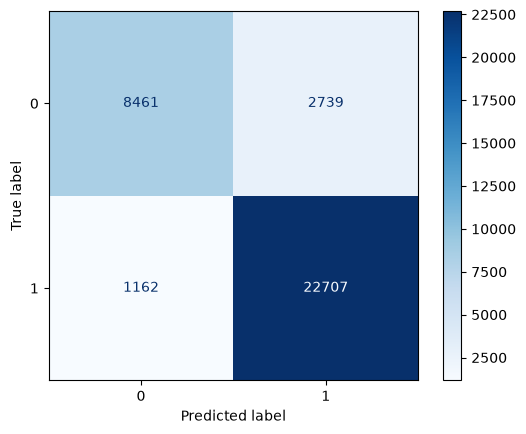

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_log_pca, x_test), grid_log_pca.best_params_)

In [ ]:
bang_pca_log = bang_sklearn(grid_log_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test)
print(bang_pca_log.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.42    0.8950     0.8902  0.9647    0.9260 0.8806        0.2003          12.96
                 8            0.31    0.9093     0.8904  0.9884    0.9368 0.8962        0.1944          13.69
                16            0.21    0.8891     0.8639  0.9936    0.9242 0.9236        0.2644          14.56


3.2.2 Bayes

In [ ]:
pipeline = Pipeline(
    [('pca', PCA(random_state=42)), ('model', GaussianNB())]
)

param_grid = [
    {'pca__n_components': [4, 8, 16],
     'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}
]

grid_nb_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=8, cv=st, scoring='f1', random_state=42)
grid_nb_pca.fit(x_train, y_train)
predict = grid_nb_pca.predict(x_test)

Accuracy: 0.9041
Precision: 0.897
Recall: 0.9706
F1_Score: 0.9323
AUC: 0.9182
Best param {'pca__n_components': 8, 'model__var_smoothing': 1e-06}


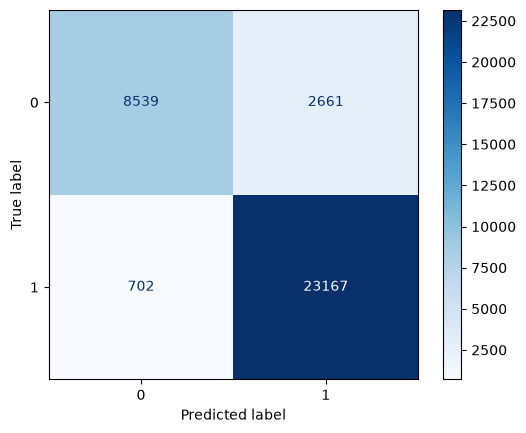

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_nb_pca, x_test), grid_nb_pca.best_params_)

In [ ]:
bang_pca_nb = bang_sklearn(grid_nb_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test)
print(bang_pca_nb.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.38    0.8983     0.8790  0.9862    0.9296 0.9209        0.1303          17.86
                 8            0.36    0.9126     0.8939  0.9889    0.9390 0.9182        0.1390          20.28
                16            0.45    0.8706     0.8945  0.9182    0.9062 0.8872        0.1615          26.83


3.2.3 KNN

In [ ]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])

param_grid = [{
    'pca__n_components': [4, 8, 16],
    'model__n_neighbors': [3, 5, 7, 11],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
}]

grid_knn_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=20, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_knn_pca.fit(x_train, y_train)
predict = grid_knn_pca.predict(x_test)

Accuracy: 0.9402
Precision: 0.9481
Recall: 0.965
F1_Score: 0.9565
AUC: 0.98
Best param {'pca__n_components': 16, 'model__weights': 'distance', 'model__n_neighbors': 7, 'model__metric': 'euclidean'}


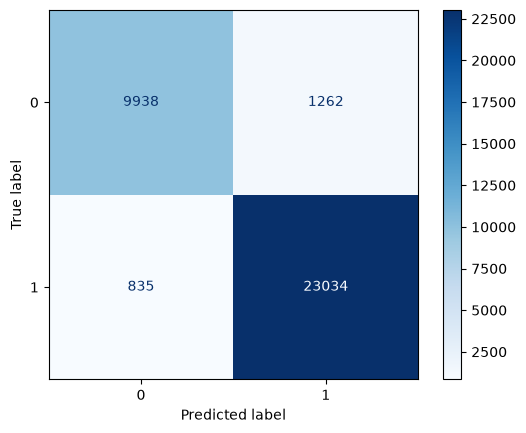

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_knn_pca, x_test), grid_knn_pca.best_params_)

In [ ]:
bang_pca_knn = bang_sklearn(grid_knn_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, dung_nguong=False)
print(bang_pca_knn.to_string(index=False))

 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4    0.9345     0.9361  0.9699    0.9527 0.9701        0.4705         143.15
                 8    0.9386     0.9460  0.9649    0.9553 0.9786        0.5672         227.87
                16    0.9402     0.9481  0.9650    0.9565 0.9800        0.1249        7735.83


3.2.4 SVM

In [ ]:
pipeline = Pipeline(
    [('pca', PCA(random_state=42)), ('model', SVC(random_state=42))]
)

param_grid = [{
    'pca__n_components': [4, 8, 16],
    'model__kernel': ['rbf'],
    'model__C': [0.1, 1, 10],
    'model__gamma': ['scale', 'auto']}]

grid_svm_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=5, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_svm_pca.fit(x_train, y_train)
predict = grid_svm_pca.predict(x_test)

Accuracy: 0.9358
Precision: 0.9159
Recall: 0.9972
F1_Score: 0.9549
AUC: 0.9761
Best param {'pca__n_components': 16, 'model__kernel': 'rbf', 'model__gamma': 'scale', 'model__C': 1}


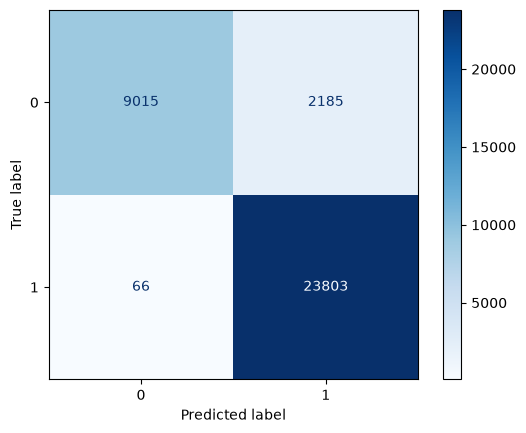

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_svm_pca, x_test), grid_svm_pca.best_params_)

In [ ]:
bang_pca_svm = bang_sklearn(grid_svm_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test, dung_nguong=False)
print(bang_pca_svm.to_string(index=False))

 So_Thanh_Phan_PCA  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4    0.9269     0.9044  0.9980    0.9489 0.9540      153.5670       61404.43
                 8    0.9305     0.9092  0.9976    0.9513 0.9671      180.1783       60804.83
                16    0.9358     0.9159  0.9972    0.9549 0.9761      258.6300       58864.62


3.2.5 DecisionTree

In [ ]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', DecisionTreeClassifier(random_state=42)),
])

param_grid = [{
    'pca__n_components': [4, 8, 16],
    'model__criterion': ['gini', 'entropy'],
    'model__splitter': ['best', 'random'],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced'],
}]

grid_dt_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=10, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_dt_pca.fit(x_train, y_train)
predict = grid_dt_pca.predict(x_test)

Accuracy: 0.9349
Precision: 0.9181
Recall: 0.993
F1_Score: 0.9541
AUC: 0.9756
Best param {'pca__n_components': 8, 'model__splitter': 'best', 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_depth': 10, 'model__criterion': 'gini', 'model__class_weight': None}


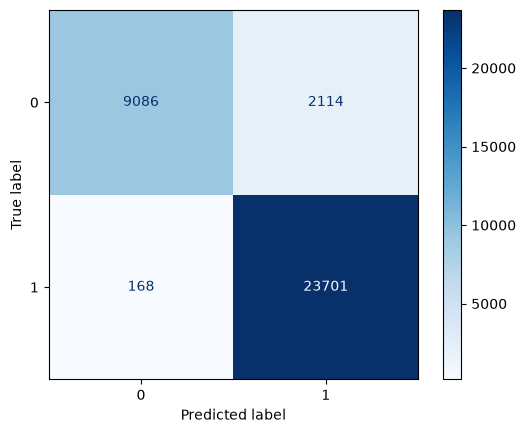

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_dt_pca, x_test), grid_dt_pca.best_params_)

In [ ]:
bang_pca_dt = bang_sklearn(grid_dt_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test)
print(bang_pca_dt.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.36    0.9294     0.9088  0.9962    0.9505 0.9684        0.5994          14.64
                 8            0.37    0.9346     0.9167  0.9943    0.9539 0.9756        1.0696          14.83
                16            0.33    0.9369     0.9192  0.9948    0.9555 0.9764        2.0667          15.64


3.2.6 XGB

In [ ]:
pipeline = Pipeline([
    ('pca', PCA(random_state=42)),
    ('model', XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)),
])

param_grid = [{
    'pca__n_components': [4, 8, 16],
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__scale_pos_weight': [1, 5],
}]

grid_xgb_pca = RandomizedSearchCV(pipeline, param_grid, n_iter=10, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_xgb_pca.fit(x_train, y_train)
predict = grid_xgb_pca.predict(x_test)

Accuracy: 0.9415
Precision: 0.9299
Recall: 0.9886
F1_Score: 0.9583
AUC: 0.9862
Best param {'pca__n_components': 16, 'model__subsample': 1.0, 'model__scale_pos_weight': 1, 'model__n_estimators': 200, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


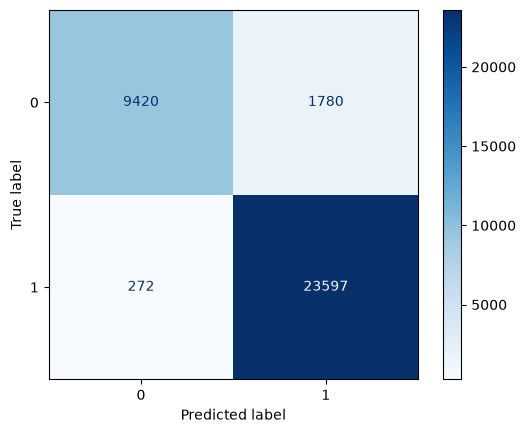

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_xgb_pca, x_test), grid_xgb_pca.best_params_)

In [ ]:
bang_pca_xgb = bang_sklearn(grid_xgb_pca, 'pca__n_components', 'So_Thanh_Phan_PCA', x_train, x_test)
print(bang_pca_xgb.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.51    0.9324     0.9154  0.9925    0.9524 0.9772        0.9896          45.15
                 8            0.49    0.9397     0.9271  0.9892    0.9572 0.9845        1.2670          46.71
                16            0.51    0.9414     0.9309  0.9872    0.9582 0.9862        1.6835          72.18


3.2.7 SGD

In [ ]:
param_grid = {'k': K_LIST, 'lr': [1e-2, 1e-3, 1e-4], 'weight_decay': [1e-4, 1e-2], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_sgd)
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'lr': 0.01, 'weight_decay': 0.01, 'epochs': 50} | OOF F1: 0.9190 | đã thử 8/18 tổ hợp


In [ ]:
bang_pca_sgd = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA')
print(bang_pca_sgd.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.32    0.8889     0.8736  0.9783    0.9230 0.8931       13.1556           1.45
                 8            0.29    0.8954     0.8709  0.9936    0.9282 0.8973        7.9496           1.42
                16            0.33    0.9098     0.8869  0.9943    0.9375 0.9195        9.3328           1.77


3.2.8 MLP

In [ ]:
param_grid = {'k': K_LIST, 'h1': [64, 128], 'h2': [32, 64], 'drop': [0.1, 0.3], 'lr': [1e-3, 5e-4], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_mlp)
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=12)

Best params: {'k': 16, 'h1': 64, 'h2': 64, 'drop': 0.1, 'lr': 0.0005, 'epochs': 50} | OOF F1: 0.9542 | đã thử 12/48 tổ hợp


In [ ]:
bang_pca_mlp = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA')
print(bang_pca_mlp.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.51    0.9289     0.9093  0.9948    0.9501 0.9692       31.6248          10.74
                 8            0.54    0.9346     0.9164  0.9947    0.9539 0.9770       78.6469          11.37
                16            0.53    0.9377     0.9204  0.9944    0.9560 0.9831       47.4531          11.95


3.2.9 CNN

In [ ]:
param_grid = {'k': K_LIST, 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.2], 'lr': [1e-3, 5e-4], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_cnn)
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=8)

Best params: {'k': 16, 'filters': 32, 'ks': 5, 'drop': 0.2, 'lr': 0.001, 'epochs': 50} | OOF F1: 0.9553 | đã thử 8/24 tổ hợp


In [ ]:
bang_pca_cnn = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA')
print(bang_pca_cnn.to_string(index=False))

 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.48    0.9296     0.9082  0.9974    0.9507 0.9725      119.2023         412.68
                 8            0.52    0.9360     0.9180  0.9948    0.9548 0.9796      103.5859         664.44
                16            0.51    0.9389     0.9238  0.9920    0.9567 0.9850      344.8958         951.38


3.2.10 Tabnet

In [ ]:
param_grid = {'k': K_LIST, 'n_d': [8, 16], 'n_steps': [3, 5], 'gamma': [1.3, 1.5], 'lr': [2e-2, 1e-2]}
huan_luyen = huan_luyen_tabnet
best_params = tim_tham_so(huan_luyen, khong_gian_pca, x_train, param_grid, n_iter=12)


Early stopping occurred at epoch 36 with best_epoch = 26 and best_val_logloss = 0.14938


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 28 with best_epoch = 18 and best_val_logloss = 0.16029


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 16 with best_epoch = 6 and best_val_logloss = 0.16853


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (111 outputs left out)

C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 32 with best_epoch = 22 and best_val_logloss = 0.17937


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Best params: {'k': 16, 'n_d': 16, 'n_steps': 3, 'gamma': 1.5, 'lr': 0.01} | OOF F1: 0.9541 | đã thử 12/48 tổ hợp


In [ ]:
bang_pca_tabnet = bang_deep(huan_luyen, khong_gian_pca, x_train, x_test, best_params, 'So_Thanh_Phan_PCA')
print(bang_pca_tabnet.to_string(index=False))


Early stopping occurred at epoch 38 with best_epoch = 28 and best_val_logloss = 0.16254


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 64 with best_epoch = 54 and best_val_logloss = 0.16008


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 31 with best_epoch = 21 and best_val_logloss = 0.16431


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (27 outputs left out)

C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 44 with best_epoch = 34 and best_val_logloss = 0.13856


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


 So_Thanh_Phan_PCA  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
                 4            0.45    0.9301     0.9096  0.9963    0.9510 0.9766      257.6954         709.30
                 8            0.47    0.9308     0.9106  0.9961    0.9514 0.9768       85.3193         592.07
                16            0.50    0.9360     0.9187  0.9941    0.9549 0.9834      250.1727         717.43


# 3.3 Feature extraction (Autoencoder)

Autoencoder học nén dữ liệu về không gian ẩn k chiều (k = 4, 8, 16), không dùng nhãn. Sau đó 10 mô hình được huấn luyện trên không gian ẩn này.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

3.3.0 Tạo và huấn luyện Autoencoder

In [ ]:
class AutoEncoder(nn.Module):
  def __init__(self, in_f, latent, h1=64, h2=32):
    super().__init__()
    self.encoder = nn.Sequential(
        nn.Linear(in_f, h1), nn.LeakyReLU(0.1),
        nn.Linear(h1, h2), nn.LeakyReLU(0.1),
        nn.Linear(h2, latent))
    self.decoder = nn.Sequential(
        nn.Linear(latent, h2), nn.LeakyReLU(0.1),
        nn.Linear(h2, h1), nn.LeakyReLU(0.1),
        nn.Linear(h1, in_f))
  def forward(self, x):
    z = self.encoder(x)
    return self.decoder(z)

In [ ]:
torch.manual_seed(42)
np.random.seed(42)


def train_autoencoder(x_tr, latent, epochs=100, lr=1e-3, patience=8, val_size=0.1):
  x_a, x_v = train_test_split(x_tr, test_size=val_size, random_state=42)
  net = AutoEncoder(x_tr.shape[1], latent).to(device)
  opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-5)
  loader = DataLoader(TensorDataset(to_t(x_a)), batch_size=256, shuffle=True)
  xv = to_t(x_v).to(device)

  def step_loss(net, batch):
    bx = batch[0].to(device)
    return nn.functional.mse_loss(net(bx), bx)

  def val_mse(net):
    return nn.functional.mse_loss(net(xv), xv).item()

  net, best = train_es(net, opt, loader, step_loss, val_mse, epochs, patience, 'min')
  print(f'  latent = {latent} | best val MSE: {best:.4f}')
  return net


def encode(net, x):
  net.eval()
  with torch.no_grad():
    return net.encoder(to_t(x).to(device)).cpu().numpy()


def recon_mse(net, x):
  net.eval()
  with torch.no_grad():
    xt = to_t(x).to(device)
    return nn.functional.mse_loss(net(xt), xt).item()

In [ ]:
z_train_parts, z_test_parts, rows = [], [], []

for k in K_LIST:
  print(f'Train Autoencoder, latent = {k}')
  t0 = time.time()
  ae = train_autoencoder(np.asarray(x_train), k)
  train_time = time.time() - t0

  z_train_parts.append(encode(ae, np.asarray(x_train)))
  z_test_parts.append(encode(ae, np.asarray(x_test)))

  rows.append({
      'So_Chieu_AE': k,
      'Recon_MSE_Train': round(recon_mse(ae, np.asarray(x_train)), 4),
      'Recon_MSE_Test': round(recon_mse(ae, np.asarray(x_test)), 4),
      'AE_Train_Time_s': round(train_time, 2),
  })

# ghép không gian ẩn của các k thành 1 ma trận: [k=4 | k=8 | k=16]
z_train_ae = np.hstack(z_train_parts)
z_test_ae = np.hstack(z_test_parts)

bang_ae_recon = pd.DataFrame(rows)
print(bang_ae_recon.to_string(index=False))
print(z_train_ae.shape, z_test_ae.shape)

Train Autoencoder, latent = 4
  latent = 4 | best val MSE: 0.0060
Train Autoencoder, latent = 8
  latent = 8 | best val MSE: 0.0028
Train Autoencoder, latent = 16
  latent = 16 | best val MSE: 0.0019
 So_Chieu_AE  Recon_MSE_Train  Recon_MSE_Test  AE_Train_Time_s
           4           0.0057          0.0058           188.77
           8           0.0027          0.0027            95.31
          16           0.0018          0.0018            75.86
(140272, 28) (35069, 28)


Lớp chọn đúng không gian ẩn k từ ma trận đã ghép, để dùng trong Pipeline giống như PCA (`ae__n_components`).

In [ ]:
def ae_slice(k, ks=(4, 8, 16)):
  start = sum(v for v in ks if v < k)
  return slice(start, start + k)

class LatentSlice(BaseEstimator, TransformerMixin):
  def __init__(self, n_components=4, ks=(4, 8, 16)):
    self.n_components = n_components
    self.ks = ks
  def fit(self, X, y=None):
    return self
  def transform(self, X):
    start = sum(v for v in self.ks if v < self.n_components)
    return X[:, start:start + self.n_components]


def khong_gian_ae(k, X_a, y_a, X_b):
  return X_a[:, ae_slice(k)], X_b[:, ae_slice(k)]

3.3.1 Logistic Regression

In [ ]:
pipeline = Pipeline([
    ('ae', LatentSlice()),
    ('model', LogisticRegression(max_iter = 3000, tol = 1e-3))
])
param_grid = [{
        'ae__n_components': [4, 8, 16],
        'model__C': [0.01, 0.1, 1, 10]}]
grid_log_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=8, cv=st, scoring='f1', random_state=42)
grid_log_ae.fit(z_train_ae, y_train)
predict = grid_log_ae.predict(z_test_ae)

Accuracy: 0.9133
Precision: 0.9136
Recall: 0.9638
F1_Score: 0.938
AUC: 0.9622
Best param {'model__C': 0.01, 'ae__n_components': 16}


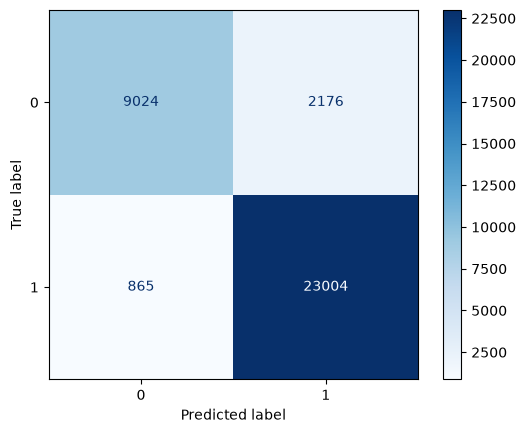

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_log_ae, z_test_ae), grid_log_ae.best_params_)

In [ ]:
bang_ae_log = bang_sklearn(grid_log_ae, 'ae__n_components', 'So_Chieu_AE', z_train_ae, z_test_ae)
print(bang_ae_log.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.52    0.8454     0.8617  0.9206    0.8902 0.8821        0.0759           1.38
           8            0.43    0.8832     0.8772  0.9632    0.9182 0.8847        0.1394           1.59
          16            0.34    0.9172     0.9027  0.9844    0.9418 0.9622        0.2629           1.45


3.3.2 Bayes

In [ ]:
pipeline = Pipeline(
    [('ae', LatentSlice()), ('model', GaussianNB())]
)

param_grid = [
    {'ae__n_components': [4, 8, 16],
     'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}
]

grid_nb_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=8, cv=st, scoring='f1', random_state=42)
grid_nb_ae.fit(z_train_ae, y_train)
predict = grid_nb_ae.predict(z_test_ae)

Accuracy: 0.7679
Precision: 0.8054
Recall: 0.869
F1_Score: 0.836
AUC: 0.8199
Best param {'model__var_smoothing': 1e-08, 'ae__n_components': 8}


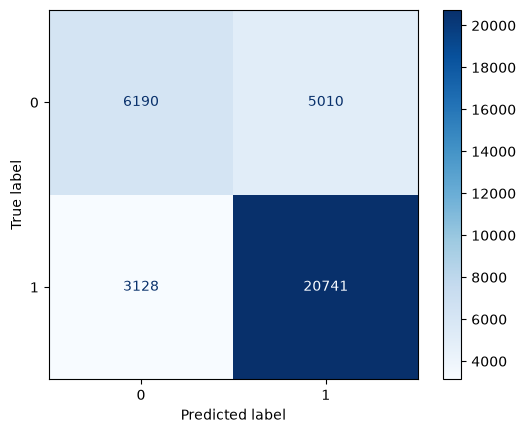

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_nb_ae, z_test_ae), grid_nb_ae.best_params_)

In [ ]:
bang_ae_nb = bang_sklearn(grid_nb_ae, 'ae__n_components', 'So_Chieu_AE', z_train_ae, z_test_ae)
print(bang_ae_nb.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.22    0.6959     0.6988  0.9723    0.8131 0.7676        0.0253           6.40
           8            0.34    0.7763     0.7796  0.9359    0.8506 0.8199        0.0268           6.42
          16            0.10    0.7868     0.8230  0.8749    0.8481 0.8725        0.0399           9.82


3.3.3 KNN

In [ ]:
pipeline = Pipeline([
    ('ae', LatentSlice()),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])

param_grid = [{
    'ae__n_components': [4, 8, 16],
    'model__n_neighbors': [3, 5, 7, 11],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
}]

grid_knn_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=20, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_knn_ae.fit(z_train_ae, y_train)
predict = grid_knn_ae.predict(z_test_ae)

Accuracy: 0.9406
Precision: 0.9426
Recall: 0.972
F1_Score: 0.9571
AUC: 0.983
Best param {'model__weights': 'distance', 'model__n_neighbors': 11, 'model__metric': 'euclidean', 'ae__n_components': 16}


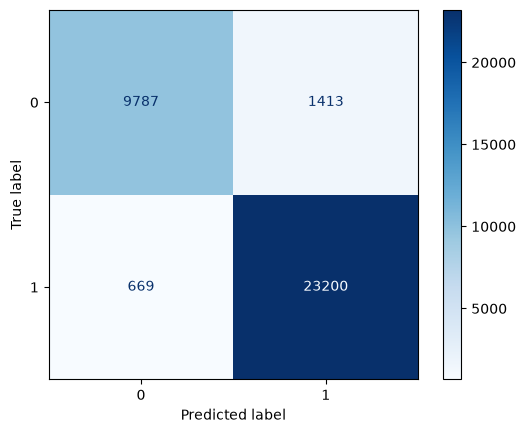

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_knn_ae, z_test_ae), grid_knn_ae.best_params_)

In [ ]:
bang_ae_knn = bang_sklearn(grid_knn_ae, 'ae__n_components', 'So_Chieu_AE', z_train_ae, z_test_ae, dung_nguong=False)
print(bang_ae_knn.to_string(index=False))

 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4    0.9361     0.9334  0.9757    0.9541 0.9771        0.2629         159.73
           8    0.9393     0.9387  0.9745    0.9563 0.9803        0.4648         354.06
          16    0.9406     0.9426  0.9720    0.9571 0.9830        0.0087        7781.28


3.3.4 SVM

In [ ]:
pipeline = Pipeline(
    [('ae', LatentSlice()), ('model', SVC(random_state=42))]
)

param_grid = [{
    'ae__n_components': [4, 8, 16],
    'model__kernel': ['rbf'],
    'model__C': [0.1, 1, 10],
    'model__gamma': ['scale', 'auto']}]

grid_svm_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=10, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_svm_ae.fit(z_train_ae, y_train)
predict = grid_svm_ae.predict(z_test_ae)

Accuracy: 0.9393
Precision: 0.9211
Recall: 0.9961
F1_Score: 0.9572
AUC: 0.9812
Best param {'model__kernel': 'rbf', 'model__gamma': 'auto', 'model__C': 10, 'ae__n_components': 8}


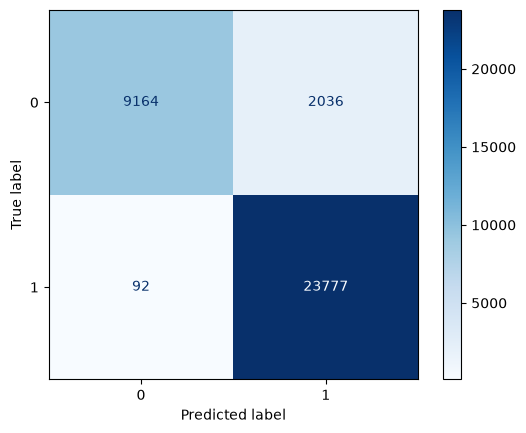

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_svm_ae, z_test_ae), grid_svm_ae.best_params_)

In [ ]:
bang_ae_svm = bang_sklearn(grid_svm_ae, 'ae__n_components', 'So_Chieu_AE', z_train_ae, z_test_ae, dung_nguong=False)
print(bang_ae_svm.to_string(index=False))

 So_Chieu_AE  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4    0.9366     0.9182  0.9955    0.9553 0.9741      356.0884       56394.46
           8    0.9393     0.9211  0.9961    0.9572 0.9812      345.2496       54416.80
          16    0.9405     0.9233  0.9953    0.9579 0.9846      328.2842       54576.84


3.3.5 DecisionTree

In [ ]:
pipeline = Pipeline([
    ('ae', LatentSlice()),
    ('model', DecisionTreeClassifier(random_state=42)),
])

param_grid = [{
    'ae__n_components': [4, 8, 16],
    'model__criterion': ['gini', 'entropy'],
    'model__splitter': ['best', 'random'],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced'],
}]

grid_dt_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=10, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_dt_ae.fit(z_train_ae, y_train)
predict = grid_dt_ae.predict(z_test_ae)

Accuracy: 0.9368
Precision: 0.9261
Recall: 0.9859
F1_Score: 0.955
AUC: 0.9773
Best param {'model__splitter': 'random', 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 15, 'model__criterion': 'entropy', 'model__class_weight': None, 'ae__n_components': 16}


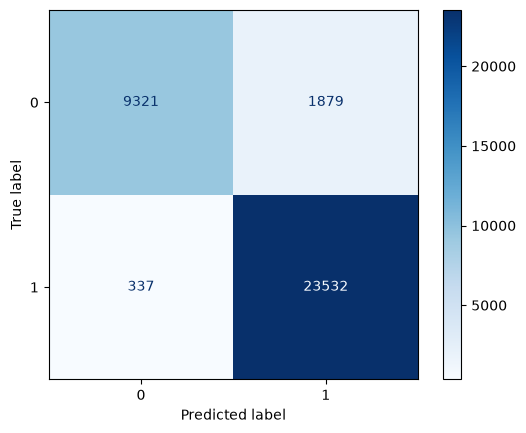

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_dt_ae, z_test_ae), grid_dt_ae.best_params_)

In [ ]:
bang_ae_dt = bang_sklearn(grid_dt_ae, 'ae__n_components', 'So_Chieu_AE', z_train_ae, z_test_ae)
print(bang_ae_dt.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.42    0.9321     0.9132  0.9947    0.9522 0.9763        0.0914           3.46
           8            0.38    0.9331     0.9147  0.9944    0.9529 0.9726        0.1501           2.42
          16            0.37    0.9377     0.9207  0.9940    0.9560 0.9773        0.2705           3.44


3.3.6 XGB

In [ ]:
pipeline = Pipeline([
    ('ae', LatentSlice()),
    ('model', XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)),
])

param_grid = [{
    'ae__n_components': [4, 8, 16],
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__scale_pos_weight': [1, 5],
}]

grid_xgb_ae = RandomizedSearchCV(pipeline, param_grid, n_iter=10, cv=st, scoring='f1', random_state=42, n_jobs=-1)
grid_xgb_ae.fit(z_train_ae, y_train)
predict = grid_xgb_ae.predict(z_test_ae)

Accuracy: 0.9409
Precision: 0.9314
Recall: 0.9858
F1_Score: 0.9578
AUC: 0.9852
Best param {'model__subsample': 1.0, 'model__scale_pos_weight': 1, 'model__n_estimators': 300, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0, 'ae__n_components': 8}


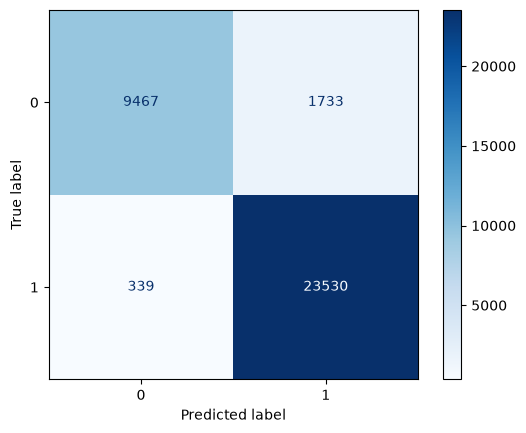

In [ ]:
in_ket_qua(y_test, predict, diem_so(grid_xgb_ae, z_test_ae), grid_xgb_ae.best_params_)

In [ ]:
bang_ae_xgb = bang_sklearn(grid_xgb_ae, 'ae__n_components', 'So_Chieu_AE', z_train_ae, z_test_ae)
print(bang_ae_xgb.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.45    0.9374     0.9209  0.9934    0.9558 0.9815        1.6379          99.04
           8            0.42    0.9412     0.9254  0.9936    0.9583 0.9852        2.0839          60.51
          16            0.43    0.9442     0.9327  0.9894    0.9602 0.9879        2.7970          62.47


3.3.7 SGD

In [ ]:
param_grid = {'k': K_LIST, 'lr': [1e-2, 1e-3, 1e-4], 'weight_decay': [1e-4, 1e-2], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_sgd)
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=8)

Best params: {'k': 16, 'lr': 0.01, 'weight_decay': 0.01, 'epochs': 50} | OOF F1: 0.9305 | đã thử 8/18 tổ hợp


In [ ]:
bang_ae_sgd = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE')
print(bang_ae_sgd.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.50    0.8608     0.8639  0.9443    0.9023 0.9105       10.4708           1.51
           8            0.46    0.8883     0.8758  0.9739    0.9223 0.8959        7.8972           1.82
          16            0.37    0.9117     0.8924  0.9895    0.9385 0.9427        9.5089           1.43


3.3.8 MLP

In [ ]:
param_grid = {'k': K_LIST, 'h1': [64, 128], 'h2': [32, 64], 'drop': [0.1, 0.3], 'lr': [1e-3, 5e-4], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_mlp)
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=12)

Best params: {'k': 16, 'h1': 128, 'h2': 32, 'drop': 0.1, 'lr': 0.001, 'epochs': 50} | OOF F1: 0.9551 | đã thử 12/48 tổ hợp


In [ ]:
bang_ae_mlp = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE')
print(bang_ae_mlp.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.55    0.9316     0.9121  0.9954    0.9519 0.9761       26.8781          12.76
           8            0.49    0.9352     0.9147  0.9978    0.9544 0.9807       37.4596          13.43
          16            0.53    0.9383     0.9242  0.9906    0.9562 0.9849       40.2718          11.61


3.3.9 CNN

In [ ]:
param_grid = {'k': K_LIST, 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.2], 'lr': [1e-3, 5e-4], 'epochs': [50]}
huan_luyen = tao_huan_luyen(tao_cnn)
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=8)

Best params: {'k': 16, 'filters': 32, 'ks': 5, 'drop': 0.2, 'lr': 0.001, 'epochs': 50} | OOF F1: 0.9550 | đã thử 8/24 tổ hợp


In [ ]:
bang_ae_cnn = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE')
print(bang_ae_cnn.to_string(index=False))

 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.50    0.9349     0.9168  0.9946    0.9541 0.9797      190.1693         414.42
           8            0.51    0.9368     0.9180  0.9961    0.9555 0.9820      110.4524         657.89
          16            0.53    0.9377     0.9218  0.9927    0.9559 0.9839      209.5636        1146.95


3.3.10 Tabnet

In [ ]:
param_grid = {'k': K_LIST, 'n_d': [8, 16], 'n_steps': [3, 5], 'gamma': [1.3, 1.5], 'lr': [2e-2, 1e-2]}
huan_luyen = huan_luyen_tabnet
best_params = tim_tham_so(huan_luyen, khong_gian_ae, z_train_ae, param_grid, n_iter=12)


Early stopping occurred at epoch 39 with best_epoch = 29 and best_val_logloss = 0.14009


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 64 with best_epoch = 54 and best_val_logloss = 0.13764


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 42 with best_epoch = 32 and best_val_logloss = 0.14117


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (111 outputs left out)

C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 65 with best_epoch = 55 and best_val_logloss = 0.15509


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Best params: {'k': 16, 'n_d': 16, 'n_steps': 3, 'gamma': 1.5, 'lr': 0.01} | OOF F1: 0.9551 | đã thử 12/48 tổ hợp


In [ ]:
bang_ae_tabnet = bang_deep(huan_luyen, khong_gian_ae, z_train_ae, z_test_ae, best_params, 'So_Chieu_AE')
print(bang_ae_tabnet.to_string(index=False))


Early stopping occurred at epoch 59 with best_epoch = 49 and best_val_logloss = 0.14852


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 55 with best_epoch = 45 and best_val_logloss = 0.15417


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 32 with best_epoch = 22 and best_val_logloss = 0.15151


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (27 outputs left out)

C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



Early stopping occurred at epoch 24 with best_epoch = 14 and best_val_logloss = 0.13607


C:\Users\Admin\PyCharmMiscProject\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


 So_Chieu_AE  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
           4            0.44    0.9326     0.9131  0.9958    0.9527 0.9785      206.3375         716.91
           8            0.48    0.9357     0.9166  0.9962    0.9547 0.9811      143.2262         693.79
          16            0.50    0.9378     0.9235  0.9907    0.9559 0.9839      141.6292         828.06


# Bước 4 : So sánh Feature Selection và Feature Extraction (PCA, Autoencoder)

4.1 Gom kết quả của 10 mô hình

In [ ]:
ten_mo_hinh = {
    'Logistic Regression': 'log',
    'Bayes': 'nb',
    'KNN': 'knn',
    'SVM': 'svm',
    'Decision Tree': 'dt',
    'XGBoost': 'xgb',
    'SGD': 'sgd',
    'MLP': 'mlp',
    'CNN': 'cnn',
    'TabNet': 'tabnet',
}

# tên cột "số chiều" của từng phương pháp
phuong_phap = {
    'Selection': ('sel', 'So_Dac_Trung_k'),
    'PCA': ('pca', 'So_Thanh_Phan_PCA'),
    'Autoencoder': ('ae', 'So_Chieu_AE'),
}

frames = []
for pp, (tien_to, cot_k) in phuong_phap.items():
    for ten, ma in ten_mo_hinh.items():
        d = globals()[f'bang_{tien_to}_{ma}'].rename(columns={cot_k: 'k'}).copy()
        d.insert(0, 'Mo_Hinh', ten)
        d.insert(1, 'Phuong_Phap', pp)
        frames.append(d)

all_results = pd.concat(frames, ignore_index=True)
print(all_results.to_string(index=False))

            Mo_Hinh Phuong_Phap  k  Best_Threshold  Accuracy  Precision  Recall  F1_Score    AUC  Train_Time_s  Infer_Time_ms
Logistic Regression   Selection  4            0.31    0.8988     0.8792  0.9868    0.9299 0.9063        0.4143           9.83
Logistic Regression   Selection  8            0.37    0.8861     0.8582  0.9974    0.9226 0.9232        0.5095          12.01
Logistic Regression   Selection 16            0.56    0.9295     0.9133  0.9904    0.9503 0.9563        0.8987          15.22
              Bayes   Selection  4            0.10    0.8959     0.8789  0.9824    0.9278 0.9167        0.3345          19.27
              Bayes   Selection  8            0.10    0.8802     0.8832  0.9497    0.9152 0.9198        0.3411          20.42
              Bayes   Selection 16            0.10    0.8070     0.8878  0.8202    0.8526 0.9039        0.4475          37.03
                KNN   Selection  4             NaN    0.9171     0.9202  0.9615    0.9404 0.9409        0.8343       1

4.2 So sánh F1 theo từng số chiều k (cùng k, ba phương pháp)

In [ ]:
print("F1 theo k:")
f1_theo_k = all_results.pivot_table(
    index='Mo_Hinh', columns=['k', 'Phuong_Phap'], values='F1_Score'
).reindex(list(ten_mo_hinh.keys()))
print(f1_theo_k.round(4).to_string())

auc_theo_k = all_results.pivot_table(
    index='Mo_Hinh', columns=['k', 'Phuong_Phap'], values='AUC'
).reindex(list(ten_mo_hinh.keys()))
print()
print("AUC theo k:")
print(auc_theo_k.round(4).to_string())

F1 theo k:
k                            4                             8                             16                  
Phuong_Phap         Autoencoder     PCA Selection Autoencoder     PCA Selection Autoencoder     PCA Selection
Mo_Hinh                                                                                                      
Logistic Regression      0.8902  0.9260    0.9299      0.9182  0.9368    0.9226      0.9418  0.9242    0.9503
Bayes                    0.8131  0.9296    0.9278      0.8506  0.9390    0.9152      0.8481  0.9062    0.8526
KNN                      0.9541  0.9527    0.9404      0.9563  0.9553    0.9458      0.9571  0.9565    0.9534
SVM                      0.9553  0.9489    0.9495      0.9572  0.9513    0.9515      0.9579  0.9549    0.9532
Decision Tree            0.9522  0.9505    0.9502      0.9529  0.9539    0.9535      0.9560  0.9555    0.9560
XGBoost                  0.9558  0.9524    0.9502      0.9583  0.9572    0.9551      0.9602  0.9582    0.9589

4.3 So sánh kết quả tốt nhất của từng mô hình

In [ ]:
best_idx = all_results.groupby(['Mo_Hinh', 'Phuong_Phap'])['F1_Score'].idxmax()
best_all = all_results.loc[best_idx]

rows_f1, rows_time = [], []
for ten in ten_mo_hinh.keys():
    r_f1 = {'Mo_Hinh': ten}
    r_time = {'Mo_Hinh': ten}
    f1_pp = {}
    for pp in phuong_phap.keys():
        b = best_all[(best_all['Mo_Hinh'] == ten) & (best_all['Phuong_Phap'] == pp)].iloc[0]
        r_f1[f'k_{pp}'] = int(b['k'])
        r_f1[f'F1_{pp}'] = b['F1_Score']
        r_f1[f'Recall_{pp}'] = b['Recall']
        r_f1[f'AUC_{pp}'] = b['AUC']
        r_time[f'Train_{pp}_s'] = b['Train_Time_s']
        r_time[f'Infer_{pp}_ms'] = b['Infer_Time_ms']
        f1_pp[pp] = b['F1_Score']
    r_f1['Tot_nhat'] = max(f1_pp, key=f1_pp.get)
    rows_f1.append(r_f1)
    rows_time.append(r_time)

bang_so_sanh = pd.DataFrame(rows_f1)
bang_thoi_gian = pd.DataFrame(rows_time)
print(bang_so_sanh.to_string(index=False))
print()
print(bang_thoi_gian.to_string(index=False))

            Mo_Hinh  k_Selection  F1_Selection  Recall_Selection  AUC_Selection  k_PCA  F1_PCA  Recall_PCA  AUC_PCA  k_Autoencoder  F1_Autoencoder  Recall_Autoencoder  AUC_Autoencoder    Tot_nhat
Logistic Regression           16        0.9503            0.9904         0.9563      8  0.9368      0.9884   0.8962             16          0.9418              0.9844           0.9622   Selection
              Bayes            4        0.9278            0.9824         0.9167      8  0.9390      0.9889   0.9182              8          0.8506              0.9359           0.8199         PCA
                KNN           16        0.9534            0.9737         0.9679     16  0.9565      0.9650   0.9800             16          0.9571              0.9720           0.9830 Autoencoder
                SVM           16        0.9532            0.9965         0.9590     16  0.9549      0.9972   0.9761             16          0.9579              0.9953           0.9846 Autoencoder
      Decision Tree 

4.4 Biểu đồ so sánh

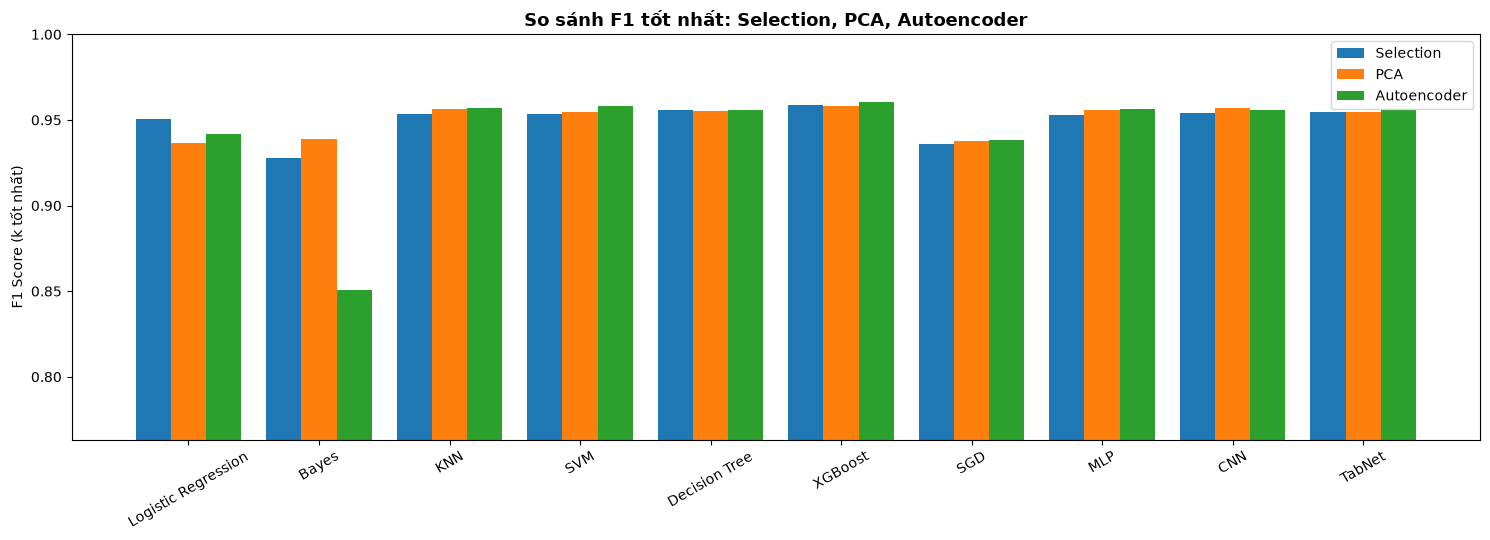

In [ ]:
mau = {'Selection': '#1f77b4', 'PCA': '#ff7f0e', 'Autoencoder': '#2ca02c'}
x = np.arange(len(bang_so_sanh))
w = 0.27

plt.figure(figsize=(15, 5.5))
for i, pp in enumerate(phuong_phap.keys()):
    plt.bar(x + (i - 1) * w, bang_so_sanh[f'F1_{pp}'], w, label=pp, color=mau[pp])
plt.xticks(x, bang_so_sanh['Mo_Hinh'], rotation=30)
plt.ylabel('F1 Score (k tốt nhất)')
plt.title('So sánh F1 tốt nhất: Selection, PCA, Autoencoder', fontsize=13, fontweight='bold')
plt.ylim(max(0, all_results['F1_Score'].min() - 0.05), 1.0)
plt.legend()
plt.tight_layout()
plt.show()

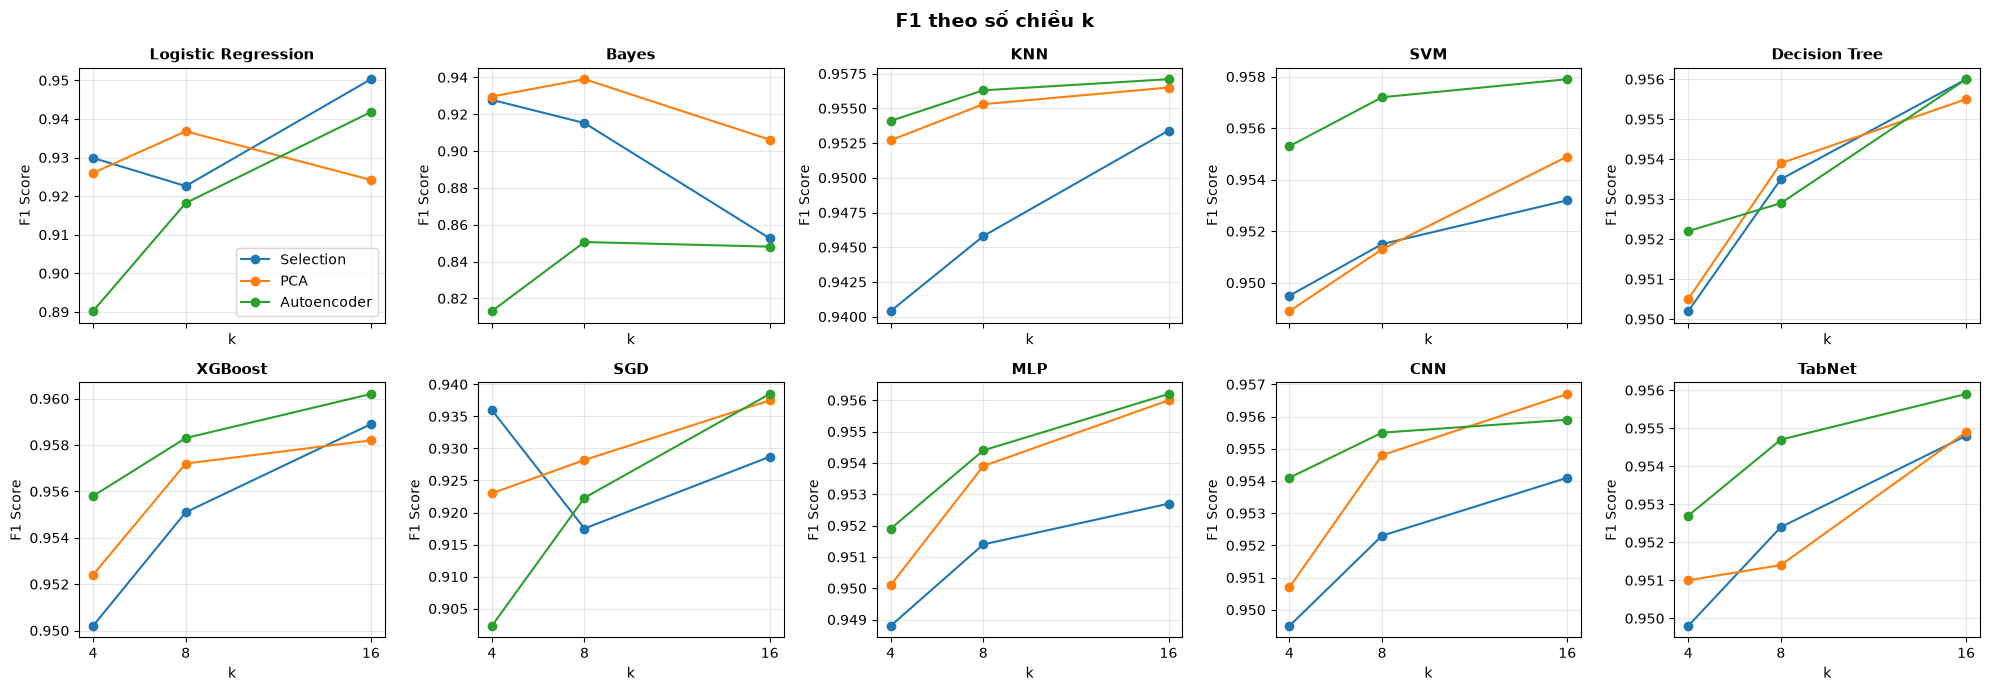

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True)
axes = axes.flatten()

for ax, ten in zip(axes, ten_mo_hinh.keys()):
    d = all_results[all_results['Mo_Hinh'] == ten]
    for pp in phuong_phap.keys():
        dd = d[d['Phuong_Phap'] == pp].sort_values('k')
        ax.plot(dd['k'], dd['F1_Score'], marker='o', label=pp, color=mau[pp])
    ax.set_title(ten, fontsize=11, fontweight='bold')
    ax.set_xticks([4, 8, 16])
    ax.set_xlabel('k')
    ax.set_ylabel('F1 Score')
    ax.grid(alpha=0.3)

axes[0].legend()
plt.suptitle('F1 theo số chiều k', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

4.5 Tổng kết

In [ ]:
tong_ket = all_results.groupby('Phuong_Phap')[['Accuracy', 'Precision', 'Recall', 'F1_Score', 'AUC', 'Train_Time_s', 'Infer_Time_ms']].mean().round(4)
print("Trung bình trên toàn bộ mô hình và k:")
print(tong_ket.to_string())

print()
print("Số mô hình mà mỗi phương pháp tốt nhất (theo F1 tốt nhất):")
print(bang_so_sanh['Tot_nhat'].value_counts().to_string())

best_overall = all_results.loc[all_results['F1_Score'].idxmax()]
print()
print(f"Cấu hình tốt nhất: {best_overall['Mo_Hinh']} | {best_overall['Phuong_Phap']} | k = {int(best_overall['k'])} | F1 = {best_overall['F1_Score']}")

Trung bình trên toàn bộ mô hình và k:
             Accuracy  Precision  Recall  F1_Score     AUC  Train_Time_s  Infer_Time_ms
Phuong_Phap                                                                            
Autoencoder    0.9081     0.8980  0.9792    0.9363  0.9510       72.3941      5948.0717
PCA            0.9231     0.9085  0.9869    0.9459  0.9545       65.0446      6452.7353
Selection      0.9181     0.9057  0.9825    0.9421  0.9466       84.6514      7857.4303

Số mô hình mà mỗi phương pháp tốt nhất (theo F1 tốt nhất):
Tot_nhat
Autoencoder    6
Selection      2
PCA            2

Cấu hình tốt nhất: XGBoost | Autoencoder | k = 16 | F1 = 0.9602


### Nhận xét các bảng kết quả ở Bước 4

#### 1. Nhận xét bảng kết quả tổng hợp 10 mô hình (Mục 4.1)
* **Sự phân hóa hiệu năng:** Các mô hình học máy phi tuyến phức tạp (XGBoost, KNN, SVM) và học sâu (MLP, CNN, TabNet) thể hiện sự vượt trội rõ rệt so với các mô hình tuyến tính/xác suất (Logistic Regression, Bayes, SGD) trên cả ba phương pháp xử lý đặc trưng.
* **Xu hướng theo chiều dữ liệu:** Hầu hết các mô hình đạt hiệu năng tối ưu tại số chiều lớn nhất ($k=16$). Tuy nhiên, đối với các thuật toán phân loại tuyến tính hoặc xác suất đơn giản như Bayes, việc gia tăng số chiều hoặc sử dụng không gian phi tuyến nén đôi khi làm giảm độ chính xác do nhiễu hoặc sự phá vỡ giả định phân phối gốc.

#### 2. Nhận xét bảng so sánh F1-Score và AUC theo số chiều $k$ (Mục 4.2)
* **F1-Score:** Autoencoder tỏ ra đặc biệt hiệu quả ở các số chiều nhỏ ($k=4, 8$) đối với các mô hình mạnh như KNN, SVM và XGBoost, giữ điểm F1 ổn định trên 0.95. Trong khi đó, PCA và Feature Selection lại giúp các mô hình nhạy cảm như Bayes và Logistic Regression đạt kết quả tốt hơn.
* **AUC-ROC:** Điểm AUC của không gian trích xuất bằng Autoencoder và PCA vượt trội hơn hẳn so với Feature Selection (đặc biệt là với SVM và các mạng nơ-ron), cho thấy không gian đặc trưng liên tục được biến đổi phi tuyến giữ được khả năng phân tách lớp tốt hơn việc chỉ lọc ra các cột gốc.

#### 3. Nhận xét bảng so sánh cấu hình tốt nhất & Thời gian xử lý (Mục 4.3)
* **Phương pháp tối ưu theo mô hình:** Autoencoder là không gian biểu diễn tốt nhất cho 6/10 mô hình (KNN, SVM, XGBoost, SGD, MLP, TabNet). Feature Selection hoạt động tốt nhất trên Logistic Regression và Decision Tree, còn PCA phù hợp nhất với Bayes và CNN.
* **Đánh đổi giữa hiệu năng và tài nguyên:**
  * **SVM và KNN** đạt điểm F1 rất cao (~0.957) trên không gian Autoencoder nhưng có thời gian suy luận (Infer Time) cực kỳ lớn (lên tới 54-74 giây đối với SVM và 7.7-9.3 giây đối với KNN), hoàn toàn không khả thi cho ứng dụng thực tế thời gian thực.
  * **XGBoost và Decision Tree** duy trì sự cân bằng hoàn hảo khi vừa đạt F1 tối ưu (~0.956 - 0.960), vừa có thời gian suy luận siêu tốc (chỉ từ 3.44 ms đến 62 ms).

#### 4. Nhận xét bảng tổng kết chung (Mục 4.5)
* **Hiệu năng trung bình:** Xét trên toàn bộ tổ hợp mô hình và số chiều, **PCA** mang lại độ chính xác trung bình F1-Score cao nhất (0.9459), theo sau sát sao bởi **Feature Selection** (0.9421) và **Autoencoder** (0.9363).
* **Khả năng tối ưu hóa:** Mặc dù có điểm trung bình thấp hơn một chút do kéo giảm hiệu năng của Bayes, **Autoencoder** vẫn là phương pháp trích xuất tạo ra nhiều cấu hình đỉnh cao nhất (chiếm ưu thế ở 6 trên 10 mô hình tốt nhất).
* **Cấu hình tốt nhất toàn diện:** Sự kết hợp giữa **XGBoost** và **Autoencoder ($k = 16$)** là giải pháp tối ưu nhất cho hệ thống, đạt F1-Score cao nhất toàn mạng (**0.9602**) đồng thời bảo đảm thời gian vận hành tối ưu.